# Laboratorio 3. Variante 5.2: Avito Demand Prediction

## Alcance

Desarrollo del nivel 5 (12 puntos) hasta completar análisis, modelado, optimización,
explicabilidad, incertidumbre, causalidad, robustez y reproducibilidad. El punto 16,
correspondiente a la preparación de la entrega en PDF, queda fuera por petición expresa.

Los CSV se procesan con Lazy API, streaming, Parquet y muestras deterministas para evitar
cargar casi 1,3 GiB de texto completo en memoria.

## 1. Importación de librerías

In [57]:
from pathlib import Path
from time import perf_counter
import gc
import importlib.util
import platform
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display
from scipy import sparse, stats
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.feature_extraction import FeatureHasher
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, learning_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD
from statsmodels.api import OLS, add_constant
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(180)
pl.Config.set_fmt_str_lengths(120)

print(f"Python: {platform.python_version()}")
print(f"Polars: {pl.__version__}")

Python: 3.14.4
Polars: 1.44.2


## 2. Localización y escaneo Lazy de los datos

In [58]:
cwd = Path.cwd().resolve()
task_candidates = [cwd, cwd / "lab03" / "task", *[p / "lab03" / "task" for p in cwd.parents]]
TASK_DIR = next(
    candidate for candidate in task_candidates
    if (candidate / "datasets" / "train.csv").is_file()
)
DATASETS_DIR = TASK_DIR / "datasets"
TRAIN_CSV = DATASETS_DIR / "train.csv"
TEST_CSV = DATASETS_DIR / "test.csv"
PARQUET_ROOT = DATASETS_DIR / "parquet"

SCAN_OPTIONS = {
    "infer_schema_length": 10_000,
    "low_memory": True,
}

training_raw = pl.scan_csv(TRAIN_CSV, **SCAN_OPTIONS)
official_test_raw = pl.scan_csv(TEST_CSV, **SCAN_OPTIONS)

print(f"train.csv: {TRAIN_CSV.stat().st_size / 1024**2:,.1f} MiB")
print(f"test.csv:  {TEST_CSV.stat().st_size / 1024**2:,.1f} MiB")
print("Los LazyFrame todavía no han cargado los archivos completos en memoria.")

train.csv: 908.8 MiB
test.csv:  315.7 MiB
Los LazyFrame todavía no han cargado los archivos completos en memoria.


### Primeras diez filas

Se muestran las primeras diez observaciones. Los textos se recortan solamente para evitar una salida demasiado grande en el notebook. Los valores originales no se modifican.

In [59]:
head_10 = (
    training_raw
    .head(10)
    .with_columns([
        pl.col("title").str.slice(0, 80),
        pl.col("description").str.slice(0, 160),
    ])
    .collect()
)
display(head_10)

item_id,user_id,region,city,parent_category_name,category_name,param_1,param_2,param_3,title,description,price,item_seq_number,activation_date,user_type,image,image_top_1,deal_probability
str,str,str,str,str,str,str,str,str,str,str,f64,i64,str,str,str,f64,f64
"""b912c3c6a6ad""","""e00f8ff2eaf9""","""Свердловская область""","""Екатеринбург""","""Личные вещи""","""Товары для детей и игрушки""","""Постельные принадлежности""",null,null,"""Кокоби(кокон для сна)""","""Кокон для сна малыша,пользовались меньше месяца.цвет серый""",400.0,2,"""2017-03-28""","""Private""","""d10c7e016e03247a3bf2d13348fe959fe6f436c1caf64c7679f17c333c959b19""",1008.0,0.12789
"""2dac0150717d""","""39aeb48f0017""","""Самарская область""","""Самара""","""Для дома и дачи""","""Мебель и интерьер""","""Другое""",null,null,"""Стойка для Одежды""","""Стойка для одежды, под вешалки. С бутика.""",3000.0,19,"""2017-03-26""","""Private""","""79c9392cc51a9c81c6eb91eceb8e552171db39d71427001e1e0859c0fb843a31""",692.0,0.0
"""ba83aefab5dc""","""91e2f88dd6e3""","""Ростовская область""","""Ростов-на-Дону""","""Бытовая электроника""","""Аудио и видео""","""Видео, DVD и Blu-ray плееры""",null,null,"""Philips bluray""","""В хорошем состоянии, домашний кинотеатр с blu ray, USB. Если настроить, то работает смарт тв / Торг""",4000.0,9,"""2017-03-20""","""Private""","""b7f250ee3f39e1fedd77c141f273703f4a9be59db4b48a8713f112c67e29bb42""",3032.0,0.43177
"""02996f1dd2ea""","""bf5cccea572d""","""Татарстан""","""Набережные Челны""","""Личные вещи""","""Товары для детей и игрушки""","""Автомобильные кресла""",null,null,"""Автокресло""","""Продам кресло от0-25кг""",2200.0,286,"""2017-03-25""","""Company""","""e6ef97e0725637ea84e3d203e82dadb43ed3cc0a1c841302bf49820803501b4b""",796.0,0.80323
"""7c90be56d2ab""","""ef50846afc0b""","""Волгоградская область""","""Волгоград""","""Транспорт""","""Автомобили""","""С пробегом""","""ВАЗ (LADA)""","""2110""","""ВАЗ 2110, 2003""","""Все вопросы по телефону.""",40000.0,3,"""2017-03-16""","""Private""","""54a687a3a0fc1d68aed99bdaaf551c5c70b761b16fd0a2c089d8376e883ed33b""",2264.0,0.20797
"""51e0962387f7""","""bbfad0b1ad0a""","""Татарстан""","""Чистополь""","""Личные вещи""","""Товары для детей и игрушки""","""Автомобильные кресла""",null,null,"""Авто люлька""","""В хорошем состоянии""",1300.0,9,"""2017-03-28""","""Private""","""eb6ad1231c59d3dc7e4020e724ffe8e4d302023ddcbb99c52a6117994dd44690""",796.0,0.80323
"""c4f260a2b48a""","""08f469d2e6f7""","""Нижегородская область""","""Нижний Новгород""","""Для дома и дачи""","""Ремонт и строительство""","""Сантехника и сауна""",null,null,"""Водонагреватель 100 литров нержавейка плоский""","""Электро водонагреватель накопительный на 100 литров Термекс ID 100V, плоский, внутренний бак из нержавейки, 2 кВт, б/у 2…",11000.0,125,"""2017-03-23""","""Private""","""0330f6ac561f5db1fa8226dd5e7e127b5671d44d075a9801ec9e6ee9d20ad2c6""",2823.0,0.0
"""6b71309d6a8a""","""fef86baa002c""","""Пермский край""","""Пермь""","""Личные вещи""","""Одежда, обувь, аксессуары""","""Женская одежда""","""Джинсы""","""26""","""Бойфренды colins""","""Бойфренды в хорошем состоянии.""",500.0,61,"""2017-03-25""","""Private""","""9bab29a519e81c14f4582024adfebd4f11a4ac71d323a62f7731e19db9702115""",567.0,0.80323
"""c5b969cb63a2""","""055825270190""","""Оренбургская область""","""Оренбург""","""Личные вещи""","""Одежда, обувь, аксессуары""","""Женская одежда""","""Платья и юбки""","""> 50 (XXL)""","""Платье""","""54 раз мер очень удобное""",500.0,85,"""2017-03-17""","""Private""","""75ce06d1f939a31dfb2af8ac55f08fa998fa336d13ee05326eb44166d47a8aed""",415.0,0.0


## 3. Dimensiones, nulos y tipos

In [60]:
def dimensions(lazy_frame: pl.LazyFrame) -> tuple[int, int]:
    schema = lazy_frame.collect_schema()
    rows = lazy_frame.select(pl.len().alias("rows")).collect(engine="streaming").item()
    return int(rows), len(schema)


train_shape = dimensions(training_raw)
test_shape = dimensions(official_test_raw)

print(f"Entrenamiento: {train_shape[0]:,} filas × {train_shape[1]} columnas")
print(f"Prueba oficial: {test_shape[0]:,} filas × {test_shape[1]} columnas")

Entrenamiento: 1,503,424 filas × 18 columnas
Prueba oficial: 508,438 filas × 17 columnas


In [61]:
def null_profile(lazy_frame: pl.LazyFrame) -> pl.DataFrame:
    columns = lazy_frame.collect_schema().names()
    values = (
        lazy_frame
        .select([
            pl.len().alias("__rows"),
            *[pl.col(column).null_count().alias(column) for column in columns],
        ])
        .collect(engine="streaming")
        .row(0, named=True)
    )
    rows = int(values.pop("__rows"))
    return (
        pl.DataFrame({
            "column": columns,
            "null_count": [values[column] for column in columns],
        })
        .with_columns((pl.col("null_count") / rows).alias("null_share"))
        .sort("null_share", descending=True)
    )


train_nulls = null_profile(training_raw)
test_nulls = null_profile(official_test_raw)

print("Nulos en entrenamiento")
display(train_nulls)
print("Nulos en prueba oficial")
display(test_nulls)

Nulos en entrenamiento


column,null_count,null_share
str,i64,f64
"""param_3""",862565,0.573734
"""param_2""",654542,0.435368
"""description""",116276,0.077341
"""image""",112588,0.074888
"""image_top_1""",112588,0.074888
"""price""",85362,0.056778
"""param_1""",61576,0.040957
"""item_id""",0,0.0
"""user_id""",0,0.0


Nulos en prueba oficial


column,null_count,null_share
str,i64,f64
"""param_3""",306331,0.602494
"""param_2""",233229,0.458717
"""image""",42609,0.083804
"""image_top_1""",42609,0.083804
"""price""",30585,0.060155
"""param_1""",22910,0.04506
"""item_id""",0,0.0
"""user_id""",0,0.0
"""region""",0,0.0


In [62]:
raw_schema = training_raw.collect_schema()
for column, dtype in raw_schema.items():
    print(f"{column:24s}: {dtype}")

item_id                 : String
user_id                 : String
region                  : String
city                    : String
parent_category_name    : String
category_name           : String
param_1                 : String
param_2                 : String
param_3                 : String
title                   : String
description             : String
price                   : Float64
item_seq_number         : Int64
activation_date         : String
user_type               : String
image                   : String
image_top_1             : Float64
deal_probability        : Float64


### Corrección de tipos

- `activation_date`: texto a fecha.
- Variables categóricas: `String` a `Categorical`.
- `item_seq_number` e `image_top_1`: enteros de 32 bits.
- `price` y `deal_probability`: flotantes de 32 bits.

`price` llega como `Float64`, no como entero, porque contiene valores decimales y nulos.

In [63]:
CATEGORICAL_COLUMNS = [
    "region",
    "city",
    "parent_category_name",
    "category_name",
    "param_1",
    "param_2",
    "param_3",
    "user_type",
]


def prepare_lazy(lazy_frame: pl.LazyFrame, has_target: bool) -> pl.LazyFrame:
    expressions = [
        pl.col("activation_date").str.to_date("%Y-%m-%d", strict=False),
        pl.col(CATEGORICAL_COLUMNS).cast(pl.Categorical),
        pl.col("item_seq_number").cast(pl.Int32),
        pl.col("image_top_1").cast(pl.Int32, strict=False),
        pl.col("price").cast(pl.Float32),
    ]
    if has_target:
        expressions.append(pl.col("deal_probability").cast(pl.Float32))

    return (
        lazy_frame
        .with_columns(expressions)
        .with_columns([
            pl.col("image").is_not_null().alias("has_image"),
            pl.col("description").is_not_null().alias("has_description"),
            pl.col("title").str.len_chars().cast(pl.Int32).alias("title_length"),
            pl.col("description").fill_null("").str.len_chars().cast(pl.Int32).alias("description_length"),
            pl.col("activation_date").dt.weekday().cast(pl.Int8).alias("activation_weekday"),
            pl.col("price").is_null().alias("price_missing"),
            pl.col("image_top_1").is_null().alias("image_top_missing"),
            pl.col("price").log1p().alias("log_price"),
            pl.when(pl.col("price").is_null()).then(pl.lit("missing"))
            .when(pl.col("price") <= 500).then(pl.lit("low"))
            .when(pl.col("price") <= 2_000).then(pl.lit("medium"))
            .when(pl.col("price") <= 10_000).then(pl.lit("high"))
            .otherwise(pl.lit("very_high"))
            .cast(pl.Categorical)
            .alias("price_tier"),
        ])
        .filter(pl.col("category_name").is_not_null())
    )


data_training = prepare_lazy(training_raw, has_target=True)
data_official_test = prepare_lazy(official_test_raw, has_target=False)

for column, dtype in data_training.collect_schema().items():
    print(f"{column:24s}: {dtype}")

item_id                 : String
user_id                 : String
region                  : Categorical
city                    : Categorical
parent_category_name    : Categorical
category_name           : Categorical
param_1                 : Categorical
param_2                 : Categorical
param_3                 : Categorical
title                   : String
description             : String
price                   : Float32
item_seq_number         : Int32
activation_date         : Date
user_type               : Categorical
image                   : String
image_top_1             : Int32
deal_probability        : Float32
has_image               : Boolean
has_description         : Boolean
title_length            : Int32
description_length      : Int32
activation_weekday      : Int8
price_missing           : Boolean
image_top_missing       : Boolean
log_price               : Float32
price_tier              : Categorical


La variable nueva `price_tier` se construye con lógica condicional. Los precios nulos forman la categoría `missing`, porque eliminar esas filas descartaría información útil. El filtro de `category_name` cumple el requisito de retirar observaciones sin categoría principal; en este dataset no elimina filas porque esa columna no tiene nulos.

## 4. Plan optimizado de Polars

In [64]:
query_example = (
    data_training
    .filter(pl.col("price").is_not_null())
    .group_by("region")
    .agg([
        pl.len().alias("ads"),
        pl.col("price").mean().alias("mean_price"),
        pl.col("deal_probability").mean().alias("mean_deal_probability"),
    ])
    .sort("ads", descending=True)
)
print(query_example.explain(optimized=True))

SORT BY [descending: [true]] [col("ads")]
  AGGREGATE[maintain_order: false]
    [len().alias("ads"), col("price").mean().alias("mean_price"), col("deal_probability").mean().alias("mean_deal_probability")] BY [col("region")]
    FROM
    simple π 3/3 ["region", "price", ... 1 other column]
      FILTER (col("category_name").is_not_null() & col("price").is_not_null())
      FROM
        simple π 4/4 ["region", "price", ... 2 other columns]
           WITH_COLUMNS:
           [col("region").strict_cast(Categorical), col("category_name").strict_cast(Categorical), col("price").cast(Float32), col("deal_probability").cast(Float32)] 
            Csv SCAN [/home/qjaricalizaya/work_university/tec-data-analisis/lab03/task/datasets/train.csv]
            PROJECT 4/18 COLUMNS
            ESTIMATED ROWS: 2023204


## 5. Conversión streaming a Parquet particionado

In [65]:
def ensure_partitioned_parquet(
    lazy_frame: pl.LazyFrame,
    destination: Path,
) -> pl.LazyFrame:
    marker = destination / "_SUCCESS"
    if not marker.exists():
        if destination.exists() and any(destination.rglob("*.parquet")):
            raise RuntimeError(
                f"Conversión incompleta detectada en {destination}. "
                "Elimina esa carpeta antes de repetir la celda."
            )
        destination.mkdir(parents=True, exist_ok=True)
        lazy_frame.sink_parquet(
            pl.PartitionBy(
                destination,
                key="activation_date",
                include_key=True,
                approximate_bytes_per_file=128 * 1024**2,
            ),
            compression="zstd",
            statistics=True,
            mkdir=True,
            engine="streaming",
        )
        marker.write_text("ok\n", encoding="utf-8")
    else:
        print(f"Se reutiliza la conversión existente: {destination}")

    return pl.scan_parquet(str(destination / "**" / "*.parquet"))


train_parquet = ensure_partitioned_parquet(data_training, PARQUET_ROOT / "train")
test_parquet = ensure_partitioned_parquet(data_official_test, PARQUET_ROOT / "test")

parquet_rows = train_parquet.select(pl.len().alias("rows")).collect(engine="streaming").item()
parquet_files = len(list((PARQUET_ROOT / "train").rglob("*.parquet")))
print(f"Filas verificadas en Parquet: {parquet_rows:,}")
print(f"Archivos Parquet de entrenamiento: {parquet_files}")

Se reutiliza la conversión existente: /home/qjaricalizaya/work_university/tec-data-analisis/lab03/task/datasets/parquet/train
Se reutiliza la conversión existente: /home/qjaricalizaya/work_university/tec-data-analisis/lab03/task/datasets/parquet/test
Filas verificadas en Parquet: 1,503,424
Archivos Parquet de entrenamiento: 21


La partición por fecha permite leer solamente los días necesarios. La marca `_SUCCESS` evita repetir una conversión costosa y también impide reutilizar silenciosamente una salida incompleta.

## 6. Muestra determinista para EDA

In [66]:
EDA_MODULO = 20
eda_sample = (
    data_training
    .filter((pl.col("item_id").hash(seed=SEED) % EDA_MODULO) == 0)
    .collect(engine="streaming")
)

print(f"Filas en la muestra EDA: {eda_sample.height:,}")
print(f"Memoria estimada: {eda_sample.estimated_size('mb'):,.1f} MiB")
display(eda_sample.head(5))

Filas en la muestra EDA: 75,818
Memoria estimada: 36.5 MiB


item_id,user_id,region,city,parent_category_name,category_name,param_1,param_2,param_3,title,description,price,item_seq_number,activation_date,user_type,image,image_top_1,deal_probability,has_image,has_description,title_length,description_length,activation_weekday,price_missing,image_top_missing,log_price,price_tier
str,str,cat,cat,cat,cat,cat,cat,cat,str,str,f32,i32,date,cat,str,i32,f32,bool,bool,i32,i32,i8,bool,bool,f32,cat
"""02996f1dd2ea""","""bf5cccea572d""","""Татарстан""","""Набережные Челны""","""Личные вещи""","""Товары для детей и игрушки""","""Автомобильные кресла""",null,null,"""Автокресло""","""Продам кресло от0-25кг""",2200.0,286,2017-03-25,"""Company""","""e6ef97e0725637ea84e3d203e82dadb43ed3cc0a1c841302bf49820803501b4b""",796,0.80323,true,true,10,22,6,false,false,7.696667,"""high"""
"""d5480bb4a6e4""","""d46200940f37""","""Ханты-Мансийский АО""","""Ханты-Мансийск""","""Недвижимость""","""Квартиры""","""Сдам""","""На длительный срок""","""1""","""1-к квартира, 25 м², 2/2 эт.""","""Сдается однокомнатная мебелированная квартира квартира. Ежемесячная плата 18 тыс.р. + свет.""",18000.0,6,2017-03-25,"""Private""","""645d3fb949cb116a00c596ca1e168d8c5ddd21cdeacc5a26b711e3921a06f536""",1396,0.58853,true,true,28,91,6,false,false,9.798182,"""very_high"""
"""645237cb3601""","""fc9a38b79414""","""Оренбургская область""","""Оренбург""","""Личные вещи""","""Товары для детей и игрушки""","""Товары для школы""",null,null,"""Атласы и Контурныя карты за 8 класс""","""Атлас история нового времени,19 век./ Контурные карты история нового времени,19 век./ Контурные карты по Географии./ Цен…",70.0,15,2017-03-21,"""Private""","""5ba63fecb66633cde074c661e0249e26af5cf370241e135ac3c7486dcab2f38e""",1040,0.13858,true,true,35,144,2,false,false,4.26268,"""low"""
"""eddd320650f3""","""9250cd567e37""","""Воронежская область""","""Воронеж""","""Личные вещи""","""Одежда, обувь, аксессуары""","""Женская одежда""","""Обувь""","""37""","""Свадебные туфли""","""Продам новые туфли фирмы Louisa Peeress 37р""",1000.0,11,2017-03-17,"""Company""","""8cb74742e39236fb3fa232950876f63324cc79ad3dbc496a65d4da8de204cbd3""",435,0.0,true,true,15,43,5,false,false,6.908755,"""medium"""
"""92013ca1fe79""","""f04d65543e01""","""Кемеровская область""","""Новокузнецк""","""Услуги""","""Предложение услуг""","""Ремонт, строительство""","""Ремонт квартиры""",null,"""Монтаж дверей, проемов, откосов, арок""","""Установка межкомнатных дверей 1200-1600руб, монтаж входной двери 1500-2500руб, облагораживание проема 1200, откосы на вх…",1000.0,160,2017-03-28,"""Company""","""e85d2c9aded83478781979d11d7f1668c82ce2e3571bea6e7ebedafa62b4604b""",1373,1.0,true,true,37,345,2,false,false,6.908755,"""medium"""


## 7. Distribuciones y valores atípicos

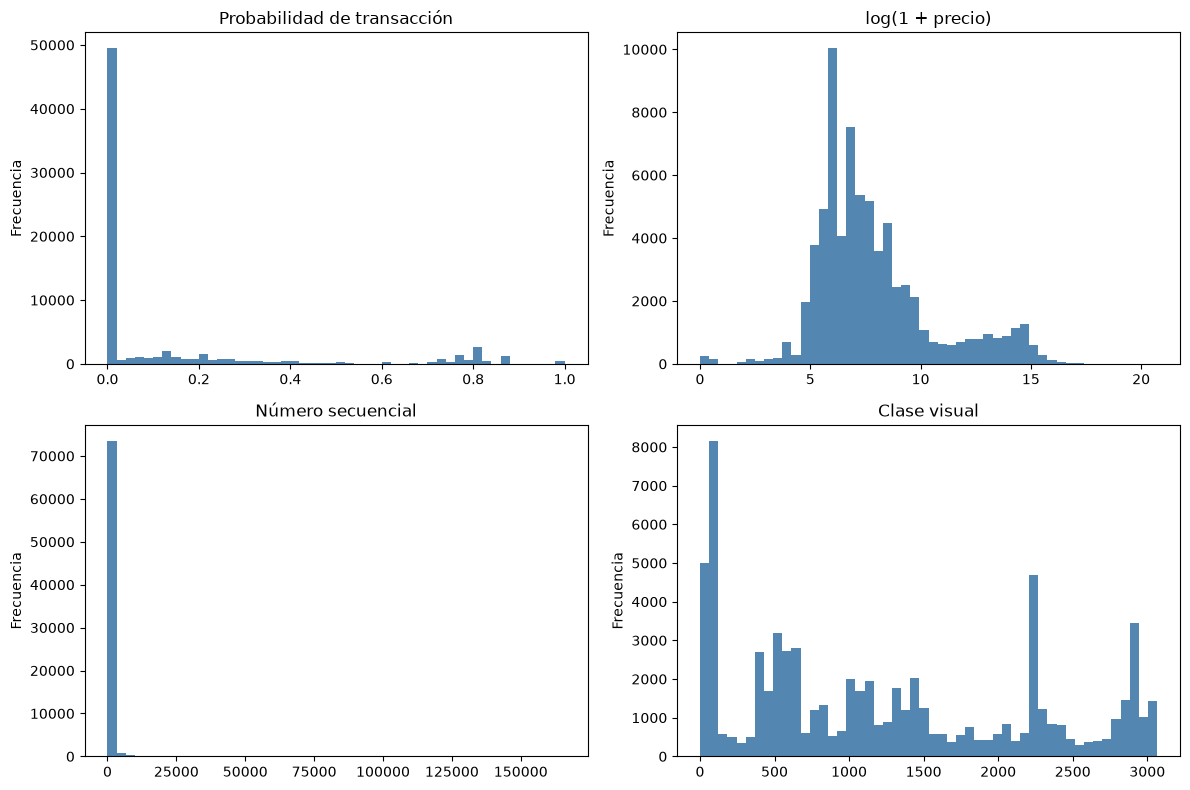

In [67]:
plot_df = pd.DataFrame(
    eda_sample.select([
        "deal_probability",
        "log_price",
        "item_seq_number",
        "image_top_1",
    ]).to_dict(as_series=False)
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column, title in zip(
    axes.ravel(),
    ["deal_probability", "log_price", "item_seq_number", "image_top_1"],
    ["Probabilidad de transacción", "log(1 + precio)", "Número secuencial", "Clase visual"],
):
    values = plot_df[column].dropna()
    ax.hist(values, bins=50, color="#3572A5", alpha=0.85)
    ax.set_title(title)
    ax.set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

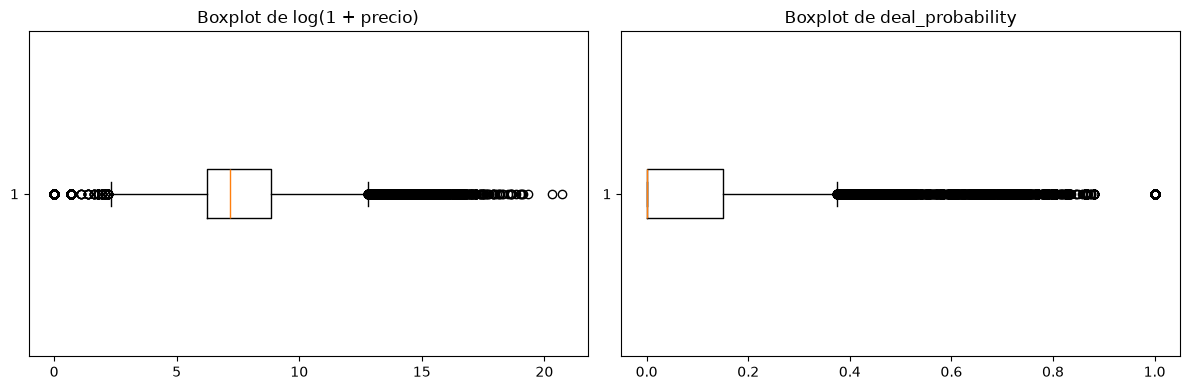

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(plot_df["log_price"].dropna(), orientation="horizontal")
axes[0].set_title("Boxplot de log(1 + precio)")
axes[1].boxplot(plot_df["deal_probability"].dropna(), orientation="horizontal")
axes[1].set_title("Boxplot de deal_probability")
plt.tight_layout()
plt.show()

In [69]:
price_values = eda_sample.get_column("price").drop_nulls().to_numpy()
q1, q3 = np.quantile(price_values, [0.25, 0.75])
iqr = q3 - q1
iqr_upper = q3 + 1.5 * iqr
iqr_outliers = price_values > iqr_upper

log_price_values = np.log1p(price_values)
z_scores = np.abs(stats.zscore(log_price_values))
z_outliers = z_scores > 3

iso_columns = ["log_price", "item_seq_number", "image_top_1", "title_length"]
iso_pd = pd.DataFrame(eda_sample.select(iso_columns).to_dict(as_series=False))
iso_matrix = SimpleImputer(strategy="median").fit_transform(iso_pd)
iso_model = IsolationForest(contamination=0.01, random_state=SEED, n_jobs=1)
iso_labels = iso_model.fit_predict(iso_matrix)

outlier_summary = pd.DataFrame({
    "método": ["IQR sobre price", "|z| > 3 sobre log_price", "Isolation Forest"],
    "atípicos": [int(iqr_outliers.sum()), int(z_outliers.sum()), int((iso_labels == -1).sum())],
    "observaciones": [len(price_values), len(log_price_values), len(iso_labels)],
})
outlier_summary["proporción"] = outlier_summary["atípicos"] / outlier_summary["observaciones"]
display(outlier_summary)

,método,atípicos,observaciones,proporción
0,IQR sobre price,12428,71476,0.173877
1,|z| > 3 sobre log_price,211,71476,0.002952
2,Isolation Forest,759,75818,0.010011


Los métodos identifican observaciones sospechosas, pero no se eliminan automáticamente. Un precio alto puede ser válido según la categoría del anuncio. La decisión final debe considerar el contexto y el rendimiento del modelo.

## 8. Estadísticas por categoría

In [70]:
category_stats = (
    data_training
    .group_by("category_name")
    .agg([
        pl.len().alias("count"),
        pl.col("deal_probability").mean().alias("mean_target"),
        pl.col("deal_probability").median().alias("median_target"),
        pl.col("deal_probability").min().alias("min_target"),
        pl.col("deal_probability").max().alias("max_target"),
    ])
    .sort("mean_target", descending=True)
    .collect(engine="streaming")
)

print("Categorías con mayor media del objetivo")
display(category_stats.head(10))
print("Categorías con menor media del objetivo")
display(category_stats.tail(10))

Categorías con mayor media del objetivo


category_name,count,mean_target,median_target,min_target,max_target
cat,u32,f32,f32,f32,f32
"""Предложение услуг""",64385,0.403123,0.33333,0.0,1.0
"""Кошки""",9951,0.297259,0.18926,0.0,0.78503
"""Автомобили""",62494,0.278427,0.15342,0.0,0.7376
"""Другие животные""",11040,0.264051,0.19475,0.0,0.78503
"""Собаки""",11612,0.252812,0.14316,0.0,0.78503
"""Бытовая техника""",33705,0.252776,0.0,0.0,0.86521
"""Мотоциклы и мототехника""",5771,0.250694,0.11378,0.0,0.74043
"""Велосипеды""",10638,0.247573,0.0,0.0,0.82668
"""Птицы""",6447,0.23834,0.19879,0.0,0.78503


Categorías con menor media del objetivo


category_name,count,mean_target,median_target,min_target,max_target
cat,u32,f32,f32,f32,f32
"""Посуда и товары для кухни""",9076,0.103222,0.0,0.0,0.86521
"""Готовый бизнес""",2028,0.099905,0.03171,0.0,0.78912
"""Красота и здоровье""",29198,0.092382,0.0,0.0,0.80323
"""Земельные участки""",16038,0.088676,0.0563,0.0,0.76824
"""Коллекционирование""",24346,0.063719,0.0,0.0,0.82668
"""Детская одежда и обувь""",270359,0.060834,0.0,0.0,0.80323
"""Часы и украшения""",15566,0.055316,0.0,0.0,0.80323
"""Недвижимость за рубежом""",117,0.053534,0.02237,0.0,0.76824
"""Одежда, обувь, аксессуары""",282753,0.046447,0.0,0.0,0.80323


In [71]:
user_type_stats = (
    data_training
    .group_by("user_type")
    .agg([
        pl.len().alias("count"),
        pl.col("deal_probability").mean().alias("mean_target"),
        pl.col("deal_probability").median().alias("median_target"),
        pl.col("price").mean().alias("mean_price"),
    ])
    .sort("mean_target", descending=True)
    .collect(engine="streaming")
)
display(user_type_stats)

user_type,count,mean_target,median_target,mean_price
cat,u32,f32,f32,f32
"""Private""",1075706,0.149557,0.0,210965.453125
"""Company""",347249,0.124513,0.0,400528.90625
"""Shop""",80469,0.062829,0.0,1.3399e6


## 9. Correlaciones

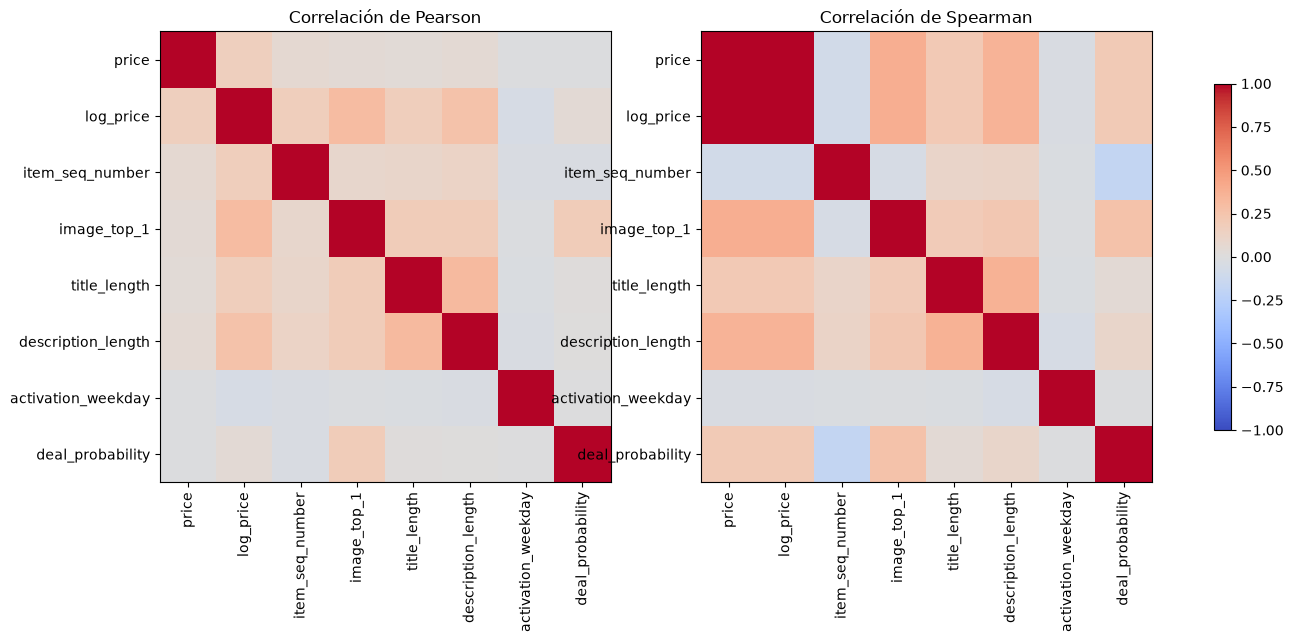

In [72]:
numeric_columns = [
    "price",
    "log_price",
    "item_seq_number",
    "image_top_1",
    "title_length",
    "description_length",
    "activation_weekday",
    "deal_probability",
]
numeric_pd = pd.DataFrame(eda_sample.select(numeric_columns).to_dict(as_series=False))

pearson_corr = numeric_pd.corr(method="pearson")
spearman_corr = numeric_pd.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, matrix, title in [
    (axes[0], pearson_corr, "Correlación de Pearson"),
    (axes[1], spearman_corr, "Correlación de Spearman"),
]:
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=90)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(title)
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.75)
plt.show()

In [73]:
def cramers_v(left: pd.Series, right: pd.Series) -> float:
    table = pd.crosstab(left.fillna("missing"), right.fillna("missing"))
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    phi2 = chi2 / n
    rows, columns = table.shape
    phi2_corrected = max(0.0, phi2 - ((columns - 1) * (rows - 1)) / max(n - 1, 1))
    rows_corrected = rows - ((rows - 1) ** 2) / max(n - 1, 1)
    columns_corrected = columns - ((columns - 1) ** 2) / max(n - 1, 1)
    denominator = max(min(columns_corrected - 1, rows_corrected - 1), 1e-12)
    return float(np.sqrt(phi2_corrected / denominator))


eda_cat_pd = pd.DataFrame(
    eda_sample.select(["region", "category_name", "user_type", "price_tier"]).to_dict(as_series=False)
)
cramer_results = pd.DataFrame([
    {"variables": "region / category_name", "Cramer's V": cramers_v(eda_cat_pd["region"], eda_cat_pd["category_name"])},
    {"variables": "user_type / price_tier", "Cramer's V": cramers_v(eda_cat_pd["user_type"], eda_cat_pd["price_tier"])},
])
display(cramer_results)

,variables,Cramer's V
0,region / category_name,0.044105
1,user_type / price_tier,0.159603


### Comprobaciones adicionales de calidad

Se comprueban duplicados, cardinalidad y correlaciones casi perfectas. Estas revisiones
completan el EDA y evitan que identificadores repetidos o variables redundantes distorsionen
la validación y los modelos lineales.

In [74]:
quality_summary = data_training.select([
    (pl.len() - pl.col("item_id").n_unique()).alias("item_id_duplicados"),
    pl.col("user_id").n_unique().alias("usuarios_unicos"),
    pl.col("city").n_unique().alias("ciudades_unicas"),
    pl.col("category_name").n_unique().alias("categorias_unicas"),
]).collect(engine="streaming")
display(quality_summary)

cardinality = data_training.select([
    pl.col(column).n_unique().alias(column) for column in CATEGORICAL_COLUMNS
]).collect(engine="streaming").transpose(
    include_header=True,
    header_name="variable",
    column_names=["cardinalidad"],
).sort("cardinalidad", descending=True)
display(cardinality)

item_id_duplicados,usuarios_unicos,ciudades_unicas,categorias_unicas
u32,u32,u32,u32
0,771769,1733,47


variable,cardinalidad
str,u32
"""city""",1733
"""param_3""",1220
"""param_1""",372
"""param_2""",272
"""category_name""",47
"""region""",28
"""parent_category_name""",9
"""user_type""",3


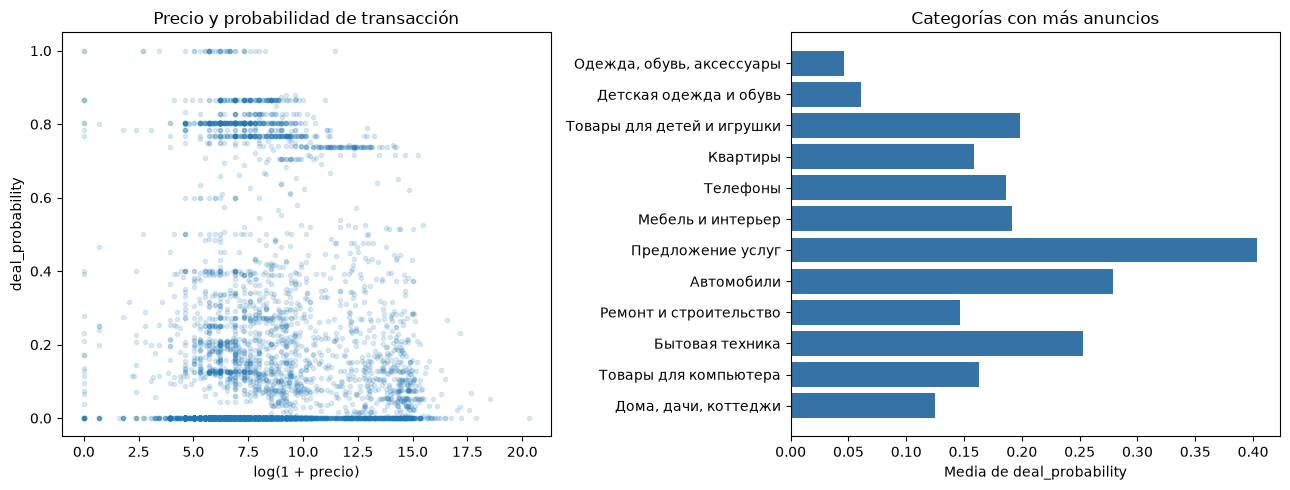

In [75]:
scatter_sample = plot_df.sample(n=min(8_000, len(plot_df)), random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(
    scatter_sample["log_price"],
    scatter_sample["deal_probability"],
    alpha=0.15,
    s=9,
)
axes[0].set_xlabel("log(1 + precio)")
axes[0].set_ylabel("deal_probability")
axes[0].set_title("Precio y probabilidad de transacción")

top_categories_pl = category_stats.sort("count", descending=True).head(12)
top_categories = pd.DataFrame(top_categories_pl.to_dict(as_series=False))
axes[1].barh(
    top_categories["category_name"].astype(str),
    top_categories["mean_target"],
    color="#3572A5",
)
axes[1].invert_yaxis()
axes[1].set_xlabel("Media de deal_probability")
axes[1].set_title("Categorías con más anuncios")
plt.tight_layout()
plt.show()

In [76]:
correlation_frame = pd.DataFrame(
    eda_sample.select(numeric_columns).to_dict(as_series=False)
)
absolute_corr = correlation_frame.corr(method="pearson").abs()
high_corr_pairs = []
for row_index, left in enumerate(absolute_corr.columns):
    for right in absolute_corr.columns[row_index + 1:]:
        value = absolute_corr.loc[left, right]
        if pd.notna(value) and value > 0.95:
            high_corr_pairs.append((left, right, value))
high_corr_table = pd.DataFrame(
    high_corr_pairs,
    columns=["variable_1", "variable_2", "correlación_absoluta"],
)
display(high_corr_table if not high_corr_table.empty else pd.DataFrame({
    "resultado": ["No hay pares numéricos con |correlación| > 0,95 en esta selección"]
}))
print("Se excluyó image_top_missing del modelado porque duplica la información de has_image.")

,resultado
0,"No hay pares numéricos con |correlación| > 0,9..."


Se excluyó image_top_missing del modelado porque duplica la información de has_image.


Los faltantes de parámetros dependen de la categoría del anuncio, por lo que resultan
plausiblemente MAR. La ausencia de imagen o descripción puede reflejar una decisión del
anunciante y, por tanto, puede ser informativa. Por eso se conservan indicadores de ausencia
y una categoría `missing` en vez de eliminar filas. `image_top_missing` se retira de las
variables del modelo porque aporta la misma información que `has_image`.

## 10. Benchmark seguro de Polars y pandas

In [77]:
BENCHMARK_ROWS = 200_000


def benchmark_polars(path: Path, n_rows: int) -> dict:
    result = {"library": "Polars"}
    start = perf_counter()
    frame = pl.read_csv(path, n_rows=n_rows, **SCAN_OPTIONS)
    result["read_seconds"] = perf_counter() - start
    result["memory_mb"] = frame.estimated_size("mb")

    start = perf_counter(); frame.null_count(); result["null_seconds"] = perf_counter() - start
    start = perf_counter(); frame.group_by("region").agg(pl.col("price").mean()); result["groupby_seconds"] = perf_counter() - start
    start = perf_counter(); frame.filter(pl.col("price") > 0); result["filter_seconds"] = perf_counter() - start
    start = perf_counter(); frame.sort("price"); result["sort_seconds"] = perf_counter() - start
    del frame
    gc.collect()
    return result


def benchmark_pandas(path: Path, n_rows: int) -> dict:
    result = {"library": "pandas"}
    start = perf_counter()
    frame = pd.read_csv(path, nrows=n_rows)
    result["read_seconds"] = perf_counter() - start
    result["memory_mb"] = frame.memory_usage(index=True, deep=True).sum() / 1024**2

    start = perf_counter(); frame.isna().sum(); result["null_seconds"] = perf_counter() - start
    start = perf_counter(); frame.groupby("region", observed=True)["price"].mean(); result["groupby_seconds"] = perf_counter() - start
    start = perf_counter(); frame.loc[frame["price"] > 0]; result["filter_seconds"] = perf_counter() - start
    start = perf_counter(); frame.sort_values("price"); result["sort_seconds"] = perf_counter() - start
    del frame
    gc.collect()
    return result


benchmark_results = pd.DataFrame([
    benchmark_polars(TRAIN_CSV, BENCHMARK_ROWS),
    benchmark_pandas(TRAIN_CSV, BENCHMARK_ROWS),
])
display(benchmark_results)

polars_row = benchmark_results.set_index("library").loc["Polars"]
pandas_row = benchmark_results.set_index("library").loc["pandas"]
speedups = pd.DataFrame({
    "operation": ["read", "null_count", "groupby", "filter", "sort"],
    "pandas_time / polars_time": [
        pandas_row["read_seconds"] / polars_row["read_seconds"],
        pandas_row["null_seconds"] / polars_row["null_seconds"],
        pandas_row["groupby_seconds"] / polars_row["groupby_seconds"],
        pandas_row["filter_seconds"] / polars_row["filter_seconds"],
        pandas_row["sort_seconds"] / polars_row["sort_seconds"],
    ],
})
display(speedups)

,library,read_seconds,memory_mb,null_seconds,groupby_seconds,filter_seconds,sort_seconds
0,Polars,0.375736,119.670477,0.000031,0.051886,0.028116,0.089894
1,pandas,2.597551,282.881047,0.156531,0.026607,0.061366,0.122678


,operation,pandas_time / polars_time
0,read,6.913228
1,null_count,5123.423688
2,groupby,0.512811
3,filter,2.182589
4,sort,1.364696


El benchmark usa exactamente las mismas 200 000 filas para ambas bibliotecas. Se limita el tamaño para evitar duplicar en memoria el CSV completo. Una razón mayor que 1 indica que Polars tardó menos en esa operación; los resultados reales pueden cambiar según el equipo y la caché del sistema.

## 11. División reproducible 80/20

In [78]:
MODEL_MODULO = 12
model_frame = (
    data_training
    .filter((pl.col("item_id").hash(seed=SEED) % MODEL_MODULO) == 0)
    .with_columns(
        (pl.col("item_id").hash(seed=SEED + 1) % 5).cast(pl.Int8).alias("split_bucket")
    )
    .collect(engine="streaming")
)

model_pd = pd.DataFrame(model_frame.to_dict(as_series=False))
train_pd = model_pd.loc[model_pd["split_bucket"] != 0].reset_index(drop=True)
test_pd = model_pd.loc[model_pd["split_bucket"] == 0].reset_index(drop=True)

split_summary = pd.DataFrame({
    "partición": ["entrenamiento", "prueba interna"],
    "filas": [len(train_pd), len(test_pd)],
})
split_summary["proporción"] = split_summary["filas"] / split_summary["filas"].sum()
display(split_summary)
print("La prueba oficial de Kaggle permanece separada y no contiene deal_probability.")

,partición,filas,proporción
0,entrenamiento,100334,0.800559
1,prueba interna,24996,0.199441


La prueba oficial de Kaggle permanece separada y no contiene deal_probability.


La muestra de modelado se obtiene con un hash estable de `item_id`, no con las primeras filas del archivo. Otro hash crea la división aproximada 80/20. El conjunto de prueba interno nunca participa en el ajuste de imputadores, escaladores, texto ni codificaciones.

## 12. VIF y selección estadística de variables

In [79]:
NUMERIC_FEATURES = [
    "log_price",
    "item_seq_number",
    "image_top_1",
    "has_image",
    "has_description",
    "title_length",
    "description_length",
    "activation_weekday",
    "price_missing",
]
TARGET = "deal_probability"

numeric_imputer = SimpleImputer(strategy="median")
numeric_scaler = StandardScaler()

X_num_train = numeric_imputer.fit_transform(train_pd[NUMERIC_FEATURES].astype(float))
X_num_test = numeric_imputer.transform(test_pd[NUMERIC_FEATURES].astype(float))
X_num_train = numeric_scaler.fit_transform(X_num_train)
X_num_test = numeric_scaler.transform(X_num_test)

y_train = train_pd[TARGET].to_numpy(dtype=np.float32)
y_test = test_pd[TARGET].to_numpy(dtype=np.float32)

VIF_FEATURES = [
    "log_price",
    "item_seq_number",
    "image_top_1",
    "title_length",
    "description_length",
    "activation_weekday",
]
vif_indices = [NUMERIC_FEATURES.index(feature) for feature in VIF_FEATURES]
vif_rows = min(20_000, len(X_num_train))
vif_matrix = X_num_train[:vif_rows, vif_indices]
vif_table = pd.DataFrame({
    "feature": VIF_FEATURES,
    "VIF": [variance_inflation_factor(vif_matrix, index) for index in range(vif_matrix.shape[1])],
}).sort_values("VIF", ascending=False)
display(vif_table)

,feature,VIF
4,description_length,1.180688
0,log_price,1.159739
3,title_length,1.137093
2,image_top_1,1.109641
1,item_seq_number,1.040453
5,activation_weekday,1.003671


In [80]:
k_numeric = min(7, len(NUMERIC_FEATURES))
selector = SelectKBest(score_func=f_regression, k=k_numeric)
selector.fit(X_num_train, y_train)
selected_numeric = [
    feature for feature, keep in zip(NUMERIC_FEATURES, selector.get_support()) if keep
]
selection_scores = pd.DataFrame({
    "feature": NUMERIC_FEATURES,
    "F_score": selector.scores_,
    "selected": selector.get_support(),
}).sort_values("F_score", ascending=False)
display(selection_scores)
print("Variables seleccionadas:", selected_numeric)

,feature,F_score,selected
2,image_top_1,3260.171557,True
4,has_description,539.540162,True
8,price_missing,507.182639,True
3,has_image,343.946549,True
0,log_price,153.309495,True
1,item_seq_number,128.822939,True
5,title_length,9.799099,True
6,description_length,0.658656,False
7,activation_weekday,0.341061,False


Variables seleccionadas: ['log_price', 'item_seq_number', 'image_top_1', 'has_image', 'has_description', 'title_length', 'price_missing']


## 13. Representación del texto: SBERT o fallback TF-IDF

In [81]:
train_text = (
    train_pd["title"].fillna("").astype(str)
    + " "
    + train_pd["description"].fillna("").astype(str).str.slice(0, 500)
).tolist()
test_text = (
    test_pd["title"].fillna("").astype(str)
    + " "
    + test_pd["description"].fillna("").astype(str).str.slice(0, 500)
).tolist()

text_start = perf_counter()
text_method = None

if importlib.util.find_spec("sentence_transformers") is not None:
    try:
        from sentence_transformers import SentenceTransformer

        sbert_model = SentenceTransformer(
            "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
            local_files_only=True,
        )
        X_text_train_32 = sbert_model.encode(
            train_text,
            batch_size=128,
            show_progress_bar=True,
            convert_to_numpy=True,
        ).astype(np.float32)
        X_text_test_32 = sbert_model.encode(
            test_text,
            batch_size=128,
            show_progress_bar=True,
            convert_to_numpy=True,
        ).astype(np.float32)
        if X_text_train_32.shape[1] != 32:
            text_pca = TruncatedSVD(n_components=32, random_state=SEED)
            X_text_train_32 = text_pca.fit_transform(X_text_train_32).astype(np.float32)
            X_text_test_32 = text_pca.transform(X_text_test_32).astype(np.float32)
        text_method = "SBERT multilingüe, reducido a 32 componentes"
    except Exception as exc:
        print(f"SBERT no disponible localmente: {type(exc).__name__}: {exc}")

if text_method is None:
    tfidf = TfidfVectorizer(
        max_features=12_000,
        min_df=5,
        ngram_range=(1, 2),
        sublinear_tf=True,
        dtype=np.float32,
    )
    train_tfidf = tfidf.fit_transform(train_text)
    test_tfidf = tfidf.transform(test_text)
    text_reducer = TruncatedSVD(n_components=32, random_state=SEED)
    X_text_train_32 = text_reducer.fit_transform(train_tfidf).astype(np.float32)
    X_text_test_32 = text_reducer.transform(test_tfidf).astype(np.float32)
    text_method = "TF-IDF + TruncatedSVD a 32 componentes (fallback permitido)"

text_seconds = perf_counter() - text_start
print(text_method)
print(f"Train text shape: {X_text_train_32.shape}")
print(f"Test text shape:  {X_text_test_32.shape}")
print(f"Tiempo: {text_seconds:.2f} s")

TF-IDF + TruncatedSVD a 32 componentes (fallback permitido)
Train text shape: (100334, 32)
Test text shape:  (24996, 32)
Tiempo: 12.87 s


El modelo multilingüe resulta más apropiado para textos rusos que un modelo exclusivamente inglés. Para evitar descargas inesperadas, SBERT se usa solamente si la biblioteca y el modelo ya están disponibles localmente. En caso contrario se aplica el fallback TF-IDF autorizado por el enunciado. El ajuste siempre utiliza únicamente los textos de entrenamiento.

## 14. Cinco codificaciones categóricas

In [82]:
MODEL_CATEGORICALS = [
    "region",
    "city",
    "parent_category_name",
    "category_name",
    "user_type",
    "price_tier",
]


def clean_category(series: pd.Series) -> pd.Series:
    return series.astype("object").where(series.notna(), "missing").astype(str)


train_categories = pd.DataFrame({
    column: clean_category(train_pd[column]) for column in MODEL_CATEGORICALS
})
test_categories = pd.DataFrame({
    column: clean_category(test_pd[column]) for column in MODEL_CATEGORICALS
})

In [83]:
def frequency_encode(train_frame: pd.DataFrame, test_frame: pd.DataFrame):
    train_output = np.zeros((len(train_frame), train_frame.shape[1]), dtype=np.float32)
    test_output = np.zeros((len(test_frame), test_frame.shape[1]), dtype=np.float32)
    for index, column in enumerate(train_frame.columns):
        frequencies = train_frame[column].value_counts(normalize=True)
        train_output[:, index] = train_frame[column].map(frequencies).fillna(0).to_numpy()
        test_output[:, index] = test_frame[column].map(frequencies).fillna(0).to_numpy()
    return sparse.csr_matrix(train_output), sparse.csr_matrix(test_output)


def categorical_tokens(frame: pd.DataFrame):
    return [
        [f"{column}={value}" for column, value in zip(frame.columns, row)]
        for row in frame.itertuples(index=False, name=None)
    ]


def smoothed_mapping(categories: pd.Series, target: np.ndarray, alpha: float, global_mean: float):
    stats_frame = pd.DataFrame({"category": categories.to_numpy(), "target": target})
    grouped = stats_frame.groupby("category", observed=True)["target"].agg(["mean", "count"])
    return ((grouped["mean"] * grouped["count"] + global_mean * alpha) / (grouped["count"] + alpha)).to_dict()


def oof_target_encode(
    train_frame: pd.DataFrame,
    test_frame: pd.DataFrame,
    target: np.ndarray,
    alpha: float = 20.0,
    n_splits: int = 5,
):
    global_mean = float(np.mean(target))
    train_output = np.zeros((len(train_frame), train_frame.shape[1]), dtype=np.float32)
    test_output = np.zeros((len(test_frame), test_frame.shape[1]), dtype=np.float32)
    folds = KFold(n_splits=n_splits, shuffle=True, random_state=SEED)

    for column_index, column in enumerate(train_frame.columns):
        for fit_index, validation_index in folds.split(train_frame):
            mapping = smoothed_mapping(
                train_frame.iloc[fit_index][column],
                target[fit_index],
                alpha,
                global_mean,
            )
            train_output[validation_index, column_index] = (
                train_frame.iloc[validation_index][column]
                .map(mapping)
                .fillna(global_mean)
                .to_numpy(dtype=np.float32)
            )

        full_mapping = smoothed_mapping(
            train_frame[column], target, alpha, global_mean
        )
        test_output[:, column_index] = (
            test_frame[column]
            .map(full_mapping)
            .fillna(global_mean)
            .to_numpy(dtype=np.float32)
        )

    return sparse.csr_matrix(train_output), sparse.csr_matrix(test_output)


def ordered_target_encode(
    train_frame: pd.DataFrame,
    test_frame: pd.DataFrame,
    target: np.ndarray,
    alpha: float = 20.0,
):
    global_mean = float(np.mean(target))
    train_output = np.zeros((len(train_frame), train_frame.shape[1]), dtype=np.float32)
    test_output = np.zeros((len(test_frame), test_frame.shape[1]), dtype=np.float32)
    rng = np.random.default_rng(SEED)

    for column_index, column in enumerate(train_frame.columns):
        values = train_frame[column].to_numpy()
        order = rng.permutation(len(values))
        sums = {}
        counts = {}
        for row_index in order:
            category = values[row_index]
            previous_sum = sums.get(category, 0.0)
            previous_count = counts.get(category, 0)
            train_output[row_index, column_index] = (
                previous_sum + alpha * global_mean
            ) / (previous_count + alpha)
            sums[category] = previous_sum + float(target[row_index])
            counts[category] = previous_count + 1

        full_mapping = {
            category: (sums[category] + alpha * global_mean) / (counts[category] + alpha)
            for category in sums
        }
        test_output[:, column_index] = (
            test_frame[column]
            .map(full_mapping)
            .fillna(global_mean)
            .to_numpy(dtype=np.float32)
        )

    return sparse.csr_matrix(train_output), sparse.csr_matrix(test_output)

In [84]:
encoding_start = perf_counter()
encoding_matrices = {}

one_hot = OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=True)
encoding_matrices["One-Hot"] = (
    one_hot.fit_transform(train_categories),
    one_hot.transform(test_categories),
)

encoding_matrices["Frequency"] = frequency_encode(train_categories, test_categories)

hasher = FeatureHasher(n_features=256, input_type="string", alternate_sign=False)
encoding_matrices["Hashing"] = (
    hasher.transform(categorical_tokens(train_categories)),
    hasher.transform(categorical_tokens(test_categories)),
)

encoding_matrices["Target OOF"] = oof_target_encode(
    train_categories, test_categories, y_train
)

encoding_matrices["CatBoost-style ordered"] = ordered_target_encode(
    train_categories, test_categories, y_train
)

print(f"Tiempo total de codificación: {perf_counter() - encoding_start:.2f} s")
for name, (train_matrix, test_matrix) in encoding_matrices.items():
    print(f"{name:24s}: train {train_matrix.shape}, test {test_matrix.shape}")

Tiempo total de codificación: 4.18 s
One-Hot                 : train (100334, 515), test (24996, 515)
Frequency               : train (100334, 6), test (24996, 6)
Hashing                 : train (100334, 256), test (24996, 256)
Target OOF              : train (100334, 6), test (24996, 6)
CatBoost-style ordered  : train (100334, 6), test (24996, 6)


## 15. Comparación de las codificaciones con Ridge

In [85]:
base_train = sparse.csr_matrix(np.hstack([X_num_train, X_text_train_32]).astype(np.float32))
base_test = sparse.csr_matrix(np.hstack([X_num_test, X_text_test_32]).astype(np.float32))


def sparse_memory_mb(matrix: sparse.spmatrix) -> float:
    matrix = matrix.tocsr()
    return (matrix.data.nbytes + matrix.indices.nbytes + matrix.indptr.nbytes) / 1024**2


comparison_rows = []
prediction_store = {}
matrix_store = {}

for encoding_name, (category_train, category_test) in encoding_matrices.items():
    X_train_encoding = sparse.hstack([base_train, category_train], format="csr")
    X_test_encoding = sparse.hstack([base_test, category_test], format="csr")

    model = Ridge(alpha=5.0, solver="lsqr")
    fit_start = perf_counter()
    model.fit(X_train_encoding, y_train)
    fit_seconds = perf_counter() - fit_start

    predict_start = perf_counter()
    predictions = np.clip(model.predict(X_test_encoding), 0.0, 1.0)
    predict_seconds = perf_counter() - predict_start

    comparison_rows.append({
        "encoding": encoding_name,
        "features": X_train_encoding.shape[1],
        "train_memory_mb": sparse_memory_mb(X_train_encoding),
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions),
    })
    prediction_store[encoding_name] = predictions
    matrix_store[encoding_name] = (X_train_encoding, X_test_encoding)

encoding_comparison = pd.DataFrame(comparison_rows).sort_values("RMSE")
display(encoding_comparison)

,encoding,features,train_memory_mb,fit_seconds,predict_seconds,MSE,RMSE,MAE,R2
0,One-Hot,556,54.096943,0.574381,0.001716,0.056887,0.238510,0.164352,0.154340
2,Hashing,297,54.049599,0.482208,0.001853,0.057093,0.238941,0.164829,0.151282
3,Target OOF,47,36.192211,0.264414,0.001897,0.057301,0.239375,0.165574,0.148194
4,CatBoost-style ordered,47,36.192211,0.210464,0.001179,0.057306,0.239386,0.165799,0.148119
1,Frequency,47,36.192211,0.205342,0.002333,0.060341,0.245643,0.172404,0.103002


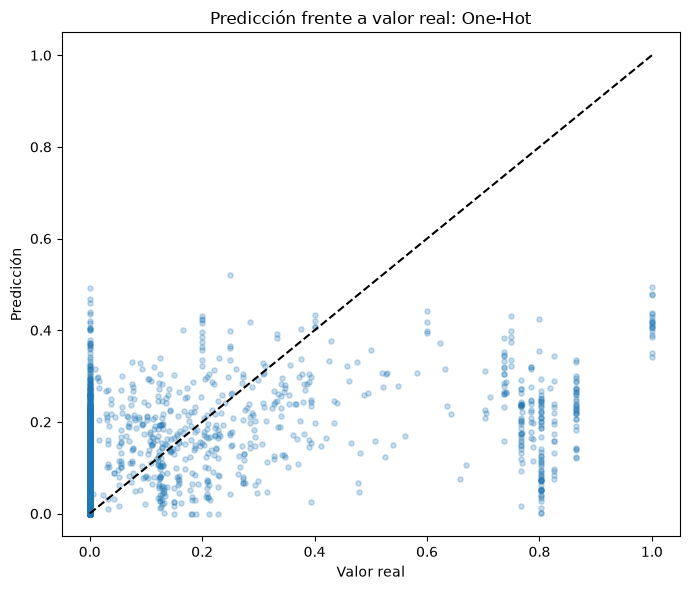

Mejor codificación según RMSE: One-Hot


In [86]:
best_encoding = encoding_comparison.iloc[0]["encoding"]
best_predictions = prediction_store[best_encoding]

sample_size = min(2_000, len(y_test))
plot_indices = np.random.default_rng(SEED).choice(len(y_test), size=sample_size, replace=False)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test[plot_indices], best_predictions[plot_indices], alpha=0.25, s=14)
ax.plot([0, 1], [0, 1], color="black", linestyle="--")
ax.set_xlabel("Valor real")
ax.set_ylabel("Predicción")
ax.set_title(f"Predicción frente a valor real: {best_encoding}")
plt.tight_layout()
plt.show()

print(f"Mejor codificación según RMSE: {best_encoding}")

## 16. Residuos y supuestos del modelo lineal

,prueba,estadístico,p_value
0,Shapiro-Wilk,0.704272,3.320805e-69
1,Breusch-Pagan,457.474401,1.208194e-95
2,Durbin-Watson,2.002209,NaN


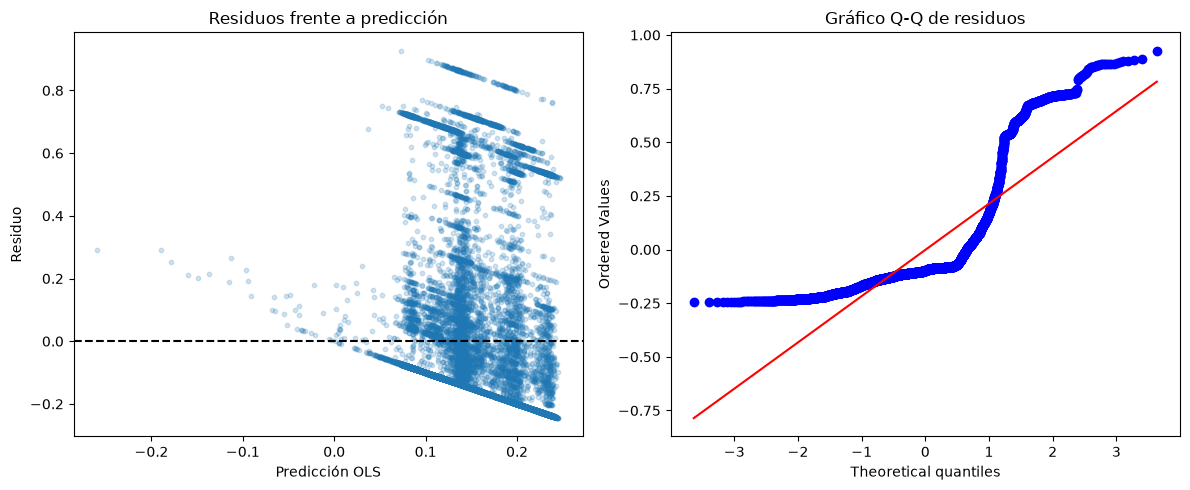

In [87]:
ols_train_rows = min(40_000, len(y_train))
ols_test_rows = min(20_000, len(y_test))
ols_X_train = add_constant(
    X_num_train[:ols_train_rows, vif_indices],
    has_constant="add",
)
ols_X_test = add_constant(
    X_num_test[:ols_test_rows, vif_indices],
    has_constant="add",
)
ols_model = OLS(y_train[:ols_train_rows], ols_X_train).fit()
ols_predictions = ols_model.predict(ols_X_test)
ols_residuals = y_test[:ols_test_rows] - ols_predictions

shapiro_sample = np.random.default_rng(SEED).choice(
    ols_residuals,
    size=min(5_000, len(ols_residuals)),
    replace=False,
)
shapiro_stat, shapiro_p = stats.shapiro(shapiro_sample)
bp_stat, bp_p, bp_f_stat, bp_f_p = het_breuschpagan(ols_residuals, ols_X_test)
dw_value = durbin_watson(ols_residuals)

assumption_tests = pd.DataFrame({
    "prueba": ["Shapiro-Wilk", "Breusch-Pagan", "Durbin-Watson"],
    "estadístico": [shapiro_stat, bp_stat, dw_value],
    "p_value": [shapiro_p, bp_p, np.nan],
})
display(assumption_tests)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(ols_predictions, ols_residuals, alpha=0.2, s=10)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_xlabel("Predicción OLS")
axes[0].set_ylabel("Residuo")
axes[0].set_title("Residuos frente a predicción")
stats.probplot(shapiro_sample, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q de residuos")
plt.tight_layout()
plt.show()

Shapiro-Wilk contrasta normalidad y Breusch-Pagan contrasta homocedasticidad. Un `p-value` inferior a 0,05 lleva a rechazar el supuesto correspondiente. Durbin-Watson cercano a 2 indica ausencia de autocorrelación lineal; su interpretación aquí es limitada porque las filas no representan una serie temporal regular por anuncio.

## 17. Curvas de aprendizaje

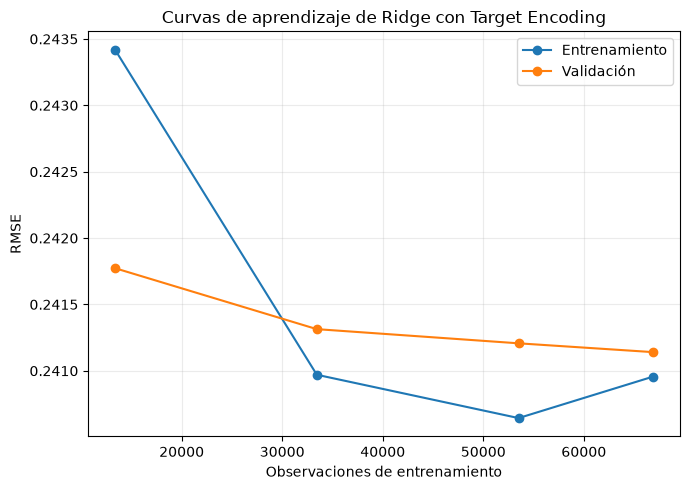

In [88]:
target_train_matrix, _ = encoding_matrices["Target OOF"]
learning_X = sparse.hstack([base_train, target_train_matrix], format="csr")
learning_model = Ridge(alpha=5.0, solver="lsqr")
cv = KFold(n_splits=3, shuffle=True, random_state=SEED)

train_sizes, train_scores, validation_scores = learning_curve(
    learning_model,
    learning_X,
    y_train,
    train_sizes=[0.2, 0.5, 0.8, 1.0],
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=1,
)

train_rmse = np.sqrt(-train_scores).mean(axis=1)
validation_rmse = np.sqrt(-validation_scores).mean(axis=1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(train_sizes, train_rmse, marker="o", label="Entrenamiento")
ax.plot(train_sizes, validation_rmse, marker="o", label="Validación")
ax.set_xlabel("Observaciones de entrenamiento")
ax.set_ylabel("RMSE")
ax.set_title("Curvas de aprendizaje de Ridge con Target Encoding")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 18. Target Encoding sin fuga de datos

In [89]:
target_train_encoded, target_test_encoded = oof_target_encode(
    train_categories,
    test_categories,
    y_train,
    alpha=20.0,
    n_splits=5,
)

target_encoding_preview = pd.DataFrame(
    target_train_encoded[:5].toarray(),
    columns=[f"TE_{column}" for column in MODEL_CATEGORICALS],
)
display(target_encoding_preview)
print("Cada fila de entrenamiento fue transformada con estadísticas calculadas sin esa fila.")
print("La prueba interna usa mapas ajustados exclusivamente con el conjunto de entrenamiento.")

,TE_region,TE_city,TE_parent_category_name,TE_category_name,TE_user_type,TE_price_tier
0,0.139519,0.136442,0.077287,0.061583,0.151521,0.108616
1,0.152819,0.134110,0.143606,0.160336,0.125867,0.160380
2,0.153797,0.186600,0.077264,0.200274,0.150812,0.109238
3,0.147485,0.135048,0.078313,0.062300,0.151425,0.124297
4,0.136301,0.136298,0.233618,0.265939,0.151369,0.174547


Cada fila de entrenamiento fue transformada con estadísticas calculadas sin esa fila.
La prueba interna usa mapas ajustados exclusivamente con el conjunto de entrenamiento.


El Target Encoding se calcula mediante cinco folds. Para transformar un fold se usan
solamente los otros cuatro. Después se construye un mapa final con todo el entrenamiento
y se aplica a la prueba interna. El objetivo de la prueba nunca participa en la
codificación.

## 19. Dependencias avanzadas y carpetas de resultados

Las siguientes secciones completan los requisitos del nivel 5. Los resultados y el pipeline
reproducible se guardan dentro de `lab03/task/artifacts` y `lab03/task/models`.

In [90]:
import shutil
import subprocess
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")
import joblib
import duckdb
import optuna
import shap
import networkx as nx

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from lime.lime_tabular import LimeTabularExplainer
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    StackingRegressor,
)
from sklearn.exceptions import ConvergenceWarning, DataConversionWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import ElasticNet, LogisticRegression, RANSACRegressor
from sklearn.metrics import mean_squared_log_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer

ARTIFACTS_DIR = TASK_DIR / "artifacts"
MODELS_DIR = TASK_DIR / "models"
ARTIFACTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

print(f"DuckDB: {duckdb.__version__}")
print(f"Optuna: {optuna.__version__}")

DuckDB: 1.5.6
Optuna: 5.0.0


## 20. Tres consultas SQL con DuckDB

In [91]:
parquet_glob = str(PARQUET_ROOT / "train" / "**" / "*.parquet")
duck = duckdb.connect()

duck_aggregation = duck.execute(f''' 
    SELECT category_name,
           COUNT(*) AS anuncios,
           AVG(deal_probability) AS media_objetivo
    FROM read_parquet('{parquet_glob}', hive_partitioning=true)
    GROUP BY category_name
    ORDER BY media_objetivo DESC
    LIMIT 10
''').fetchdf()

duck_window = duck.execute(f'''
    SELECT category_name, item_id, deal_probability,
           ROW_NUMBER() OVER (
               PARTITION BY category_name
               ORDER BY deal_probability DESC, item_id
           ) AS posición_en_categoría
    FROM read_parquet('{parquet_glob}', hive_partitioning=true)
    QUALIFY posición_en_categoría <= 3
    ORDER BY category_name, posición_en_categoría
    LIMIT 30
''').fetchdf()

duck_join = duck.execute(f'''
    WITH region_stats AS (
        SELECT region,
               COUNT(*) AS anuncios_region,
               AVG(deal_probability) AS media_region
        FROM read_parquet('{parquet_glob}', hive_partitioning=true)
        GROUP BY region
    ),
    category_region AS (
        SELECT region, category_name,
               COUNT(*) AS anuncios_categoria,
               AVG(deal_probability) AS media_categoria
        FROM read_parquet('{parquet_glob}', hive_partitioning=true)
        GROUP BY region, category_name
    )
    SELECT c.region, c.category_name, c.anuncios_categoria,
           c.media_categoria, r.anuncios_region, r.media_region
    FROM category_region c
    JOIN region_stats r USING (region)
    ORDER BY c.anuncios_categoria DESC
    LIMIT 15
''').fetchdf()

print("Consulta 1: agregación")
display(duck_aggregation)
print("Consulta 2: función de ventana")
display(duck_window)
print("Consulta 3: JOIN")
display(duck_join)
duck.close()

Consulta 1: agregación


,category_name,anuncios,media_objetivo
0,Предложение услуг,64385,0.403123
1,Кошки,9951,0.297259
2,Автомобили,62494,0.278427
3,Другие животные,11040,0.264051
4,Собаки,11612,0.252812
5,Бытовая техника,33705,0.252776
6,Мотоциклы и мототехника,5771,0.250694
7,Велосипеды,10638,0.247573
8,Птицы,6447,0.238340
9,Водный транспорт,2180,0.229866


Consulta 2: función de ventana


,category_name,item_id,deal_probability,posición_en_categoría
0,Автомобили,0003ef9d7cf6,0.73760,1
1,Автомобили,00156a98c6e3,0.73760,2
2,Автомобили,002046f31173,0.73760,3
3,Аквариум,004e8300a971,0.78503,1
4,Аквариум,0172bff8e476,0.78503,2
5,Аквариум,018054d3bbd5,0.78503,3
6,Аудио и видео,00032bea46e5,0.76786,1
7,Аудио и видео,001ac07fe8a3,0.76786,2
8,Аудио и видео,0032c4c80dc3,0.76786,3
9,Билеты и путешествия,002c51318058,0.82668,1


Consulta 3: JOIN


,region,category_name,anuncios_categoria,media_categoria,anuncios_region,media_region
0,Свердловская область,"Одежда, обувь, аксессуары",21400,0.046817,94475,0.122004
1,Краснодарский край,"Одежда, обувь, аксессуары",20239,0.039409,141416,0.147066
2,Свердловская область,Детская одежда и обувь,19829,0.060329,94475,0.122004
3,Нижегородская область,Детская одежда и обувь,15793,0.076358,73643,0.146608
4,Ростовская область,"Одежда, обувь, аксессуары",15709,0.043797,89995,0.135944
5,Краснодарский край,Квартиры,15325,0.116650,141416,0.147066
6,Челябинская область,Детская одежда и обувь,15265,0.070225,78339,0.143229
7,Самарская область,"Одежда, обувь, аксессуары",14739,0.046378,73407,0.136721
8,Челябинская область,"Одежда, обувь, аксессуары",14646,0.053250,78339,0.143229
9,Пермский край,Детская одежда и обувь,14433,0.074839,62704,0.143685


La agregación identifica categorías con mayor demanda media. La ventana conserva los tres
anuncios con mayor objetivo dentro de cada categoría sin perder el detalle por fila. El
`JOIN` combina estadísticas de categoría y región para comparar cada segmento con su contexto
regional.

## 21. Modelos de regresión y stacking

In [92]:
target_train_matrix, target_test_matrix = encoding_matrices["Target OOF"]
X_model_train_sparse = sparse.hstack(
    [base_train, target_train_matrix],
    format="csr",
)
X_model_test_sparse = sparse.hstack(
    [base_test, target_test_matrix],
    format="csr",
)

MODEL_FEATURE_NAMES = (
    NUMERIC_FEATURES
    + [f"text_{index:02d}" for index in range(X_text_train_32.shape[1])]
    + [f"TE_{column}" for column in MODEL_CATEGORICALS]
)

advanced_rng = np.random.default_rng(SEED)
advanced_rows = min(40_000, len(y_train))
advanced_indices = np.sort(
    advanced_rng.choice(len(y_train), size=advanced_rows, replace=False)
)
X_advanced_train = X_model_train_sparse[advanced_indices].toarray().astype(np.float32)
y_advanced_train = y_train[advanced_indices]
X_advanced_test = X_model_test_sparse.toarray().astype(np.float32)

print(f"Entrenamiento avanzado: {X_advanced_train.shape}")
print(f"Prueba interna:       {X_advanced_test.shape}")
print(f"Características:      {len(MODEL_FEATURE_NAMES)}")

Entrenamiento avanzado: (40000, 47)
Prueba interna:       (24996, 47)
Características:      47


In [93]:
def regression_metrics(name, model, X_fit, y_fit, X_eval, y_eval):
    fit_start = perf_counter()
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=ConvergenceWarning)
        model.fit(X_fit, y_fit)
    fit_seconds = perf_counter() - fit_start

    predict_start = perf_counter()
    prediction = np.clip(model.predict(X_eval), 0.0, 1.0)
    predict_seconds = perf_counter() - predict_start
    mse = mean_squared_error(y_eval, prediction)
    return {
        "modelo": name,
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_eval, prediction),
        "R2": r2_score(y_eval, prediction),
        "RMSLE": np.sqrt(mean_squared_log_error(y_eval, prediction)),
        "fit_seconds": fit_seconds,
        "inference_ms_per_row": 1000 * predict_seconds / len(y_eval),
    }, prediction


candidate_models = {
    "Ridge baseline": Ridge(alpha=5.0, solver="lsqr"),
    "ElasticNet": ElasticNet(
        alpha=0.0005,
        l1_ratio=0.25,
        max_iter=3_000,
        random_state=SEED,
    ),
    "LightGBM": LGBMRegressor(
        n_estimators=250,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=30,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=SEED,
        n_jobs=2,
        verbosity=-1,
    ),
    "CatBoost": CatBoostRegressor(
        iterations=250,
        depth=7,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=SEED,
        verbose=False,
        thread_count=2,
        task_type="CPU",
    ),
    "Regresión cuantil": HistGradientBoostingRegressor(
        loss="quantile",
        quantile=0.5,
        max_iter=150,
        max_leaf_nodes=31,
        learning_rate=0.06,
        random_state=SEED,
    ),
    "RANSAC": RANSACRegressor(
        estimator=Ridge(alpha=2.0),
        min_samples=0.10,
        residual_threshold=0.25,
        max_trials=40,
        random_state=SEED,
    ),
    "Red neuronal MLP (fallback CPU)": MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        early_stopping=True,
        max_iter=80,
        batch_size=512,
        random_state=SEED,
    ),
}

advanced_results = []
advanced_predictions = {}
fitted_models = {}
for model_name, estimator in candidate_models.items():
    result, prediction = regression_metrics(
        model_name,
        estimator,
        X_advanced_train,
        y_advanced_train,
        X_advanced_test,
        y_test,
    )
    advanced_results.append(result)
    advanced_predictions[model_name] = prediction
    fitted_models[model_name] = estimator
    print(f"{model_name:34s} RMSE={result['RMSE']:.5f}")

advanced_comparison = pd.DataFrame(advanced_results).sort_values("RMSE")
display(advanced_comparison)

Ridge baseline                     RMSE=0.23954
ElasticNet                         RMSE=0.24049
LightGBM                           RMSE=0.23454
CatBoost                           RMSE=0.23514
Regresión cuantil                  RMSE=0.29340
RANSAC                             RMSE=0.25609
Red neuronal MLP (fallback CPU)    RMSE=0.24012


,modelo,MSE,RMSE,MAE,R2,RMSLE,fit_seconds,inference_ms_per_row
2,LightGBM,0.055008,0.234538,0.159867,0.182276,0.175006,1.248532,0.007103
3,CatBoost,0.055291,0.235140,0.161283,0.178072,0.175470,3.769287,0.000352
0,Ridge baseline,0.057379,0.239540,0.166018,0.147021,0.178968,1.238602,0.000023
6,Red neuronal MLP (fallback CPU),0.057657,0.240119,0.172994,0.142891,0.181569,2.568732,0.001824
1,ElasticNet,0.057835,0.240490,0.167859,0.140244,0.179484,0.084119,0.003273
5,RANSAC,0.065583,0.256091,0.137813,0.025073,0.187435,3.722289,0.003192
4,Regresión cuantil,0.086084,0.293401,0.138365,-0.279691,0.221281,0.476325,0.000287


In [94]:
stacking_estimators = [
    ("ridge", Ridge(alpha=5.0, solver="lsqr")),
    ("elastic", ElasticNet(
        alpha=0.0005,
        l1_ratio=0.25,
        max_iter=2_000,
        random_state=SEED,
    )),
    ("rf", RandomForestRegressor(
        n_estimators=60,
        max_depth=12,
        min_samples_leaf=5,
        random_state=SEED,
        n_jobs=2,
    )),
    ("lgbm", LGBMRegressor(
        n_estimators=150,
        learning_rate=0.06,
        num_leaves=31,
        random_state=SEED,
        n_jobs=2,
        verbosity=-1,
    )),
]
stacking_model = StackingRegressor(
    estimators=stacking_estimators,
    final_estimator=Ridge(alpha=2.0),
    cv=3,
    n_jobs=1,
    passthrough=False,
)
stacking_result, stacking_prediction = regression_metrics(
    "Stacking (4 bases + Ridge)",
    stacking_model,
    X_advanced_train,
    y_advanced_train,
    X_advanced_test,
    y_test,
)
advanced_results.append(stacking_result)
advanced_predictions[stacking_result["modelo"]] = stacking_prediction
fitted_models[stacking_result["modelo"]] = stacking_model
advanced_comparison = pd.DataFrame(advanced_results).sort_values("RMSE")
display(advanced_comparison)

base_names = ["Ridge baseline", "ElasticNet", "LightGBM"]
base_best_rmse = advanced_comparison.loc[
    advanced_comparison["modelo"].isin(base_names), "RMSE"
].min()
print(
    "Mejora del stacking frente al mejor componente comparable: "
    f"{base_best_rmse - stacking_result['RMSE']:+.5f} RMSE"
)

,modelo,MSE,RMSE,MAE,R2,RMSLE,fit_seconds,inference_ms_per_row
7,Stacking (4 bases + Ridge),0.054972,0.234462,0.159735,0.182803,0.174932,104.396577,0.015492
2,LightGBM,0.055008,0.234538,0.159867,0.182276,0.175006,1.248532,0.007103
3,CatBoost,0.055291,0.235140,0.161283,0.178072,0.175470,3.769287,0.000352
0,Ridge baseline,0.057379,0.239540,0.166018,0.147021,0.178968,1.238602,0.000023
6,Red neuronal MLP (fallback CPU),0.057657,0.240119,0.172994,0.142891,0.181569,2.568732,0.001824
1,ElasticNet,0.057835,0.240490,0.167859,0.140244,0.179484,0.084119,0.003273
5,RANSAC,0.065583,0.256091,0.137813,0.025073,0.187435,3.722289,0.003192
4,Regresión cuantil,0.086084,0.293401,0.138365,-0.279691,0.221281,0.476325,0.000287


Mejora del stacking frente al mejor componente comparable: +0.00008 RMSE


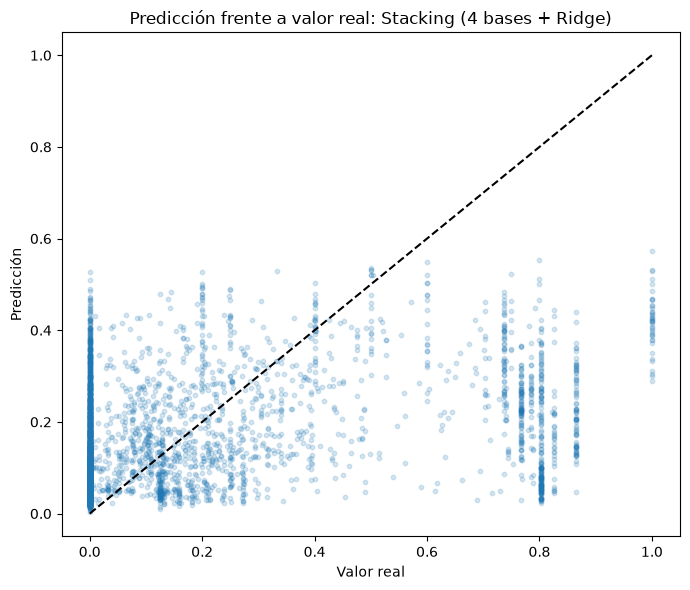

In [95]:
best_initial_name = advanced_comparison.iloc[0]["modelo"]
best_initial_prediction = advanced_predictions[best_initial_name]
fig, ax = plt.subplots(figsize=(7, 6))
plot_limit = min(5_000, len(y_test))
ax.scatter(
    y_test[:plot_limit],
    best_initial_prediction[:plot_limit],
    alpha=0.18,
    s=10,
)
ax.plot([0, 1], [0, 1], linestyle="--", color="black")
ax.set_xlabel("Valor real")
ax.set_ylabel("Predicción")
ax.set_title(f"Predicción frente a valor real: {best_initial_name}")
plt.tight_layout()
plt.show()

## 22. Optimización con Optuna: TPE, poda y 200 pruebas

In [96]:
opt_indices_train, opt_indices_valid = train_test_split(
    np.arange(len(X_advanced_train)),
    test_size=0.25,
    random_state=SEED,
)
# Se limita la muestra de búsqueda para ejecutar 200 pruebas sin utilizar la prueba final.
opt_indices_train = opt_indices_train[:15_000]
opt_indices_valid = opt_indices_valid[:5_000]
X_opt_train = X_advanced_train[opt_indices_train]
y_opt_train = y_advanced_train[opt_indices_train]
X_opt_valid = X_advanced_train[opt_indices_valid]
y_opt_valid = y_advanced_train[opt_indices_valid]


def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 80, 320),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 95),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.65, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
    }
    estimator = LGBMRegressor(
        **params,
        random_state=SEED,
        n_jobs=2,
        verbosity=-1,
    )

    def pruning_callback(environment):
        if environment.iteration % 10 != 0:
            return
        rmse_value = environment.evaluation_result_list[0][2]
        trial.report(rmse_value, step=environment.iteration)
        if trial.should_prune():
            raise optuna.TrialPruned()

    estimator.fit(
        X_opt_train,
        y_opt_train,
        eval_X=X_opt_valid,
        eval_y=y_opt_valid,
        eval_metric="rmse",
        callbacks=[pruning_callback],
    )
    prediction = np.clip(estimator.predict(X_opt_valid), 0.0, 1.0)
    return float(np.sqrt(mean_squared_error(y_opt_valid, prediction)))


optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=20,
        n_warmup_steps=20,
        interval_steps=10,
    ),
)
optimization_start = perf_counter()
study.optimize(objective, n_trials=200, show_progress_bar=False)
optimization_seconds = perf_counter() - optimization_start

print(f"Pruebas terminadas: {len(study.trials)}")
print(f"Pruebas podadas: {sum(t.state.name == 'PRUNED' for t in study.trials)}")
print(f"Mejor RMSE de validación: {study.best_value:.6f}")
print(f"Tiempo de optimización: {optimization_seconds:.1f} s")
display(pd.DataFrame([study.best_params]).T.rename(columns={0: "mejor_valor"}))
joblib.dump(study, ARTIFACTS_DIR / "optuna_study.joblib")

Pruebas terminadas: 200
Pruebas podadas: 130
Mejor RMSE de validación: 0.235394
Tiempo de optimización: 114.3 s


,mejor_valor
n_estimators,201.000000
learning_rate,0.035729
num_leaves,82.000000
max_depth,7.000000
min_child_samples,89.000000
subsample,0.980541
colsample_bytree,0.985032
reg_lambda,4.186197


['/home/qjaricalizaya/work_university/tec-data-analisis/lab03/task/artifacts/optuna_study.joblib']

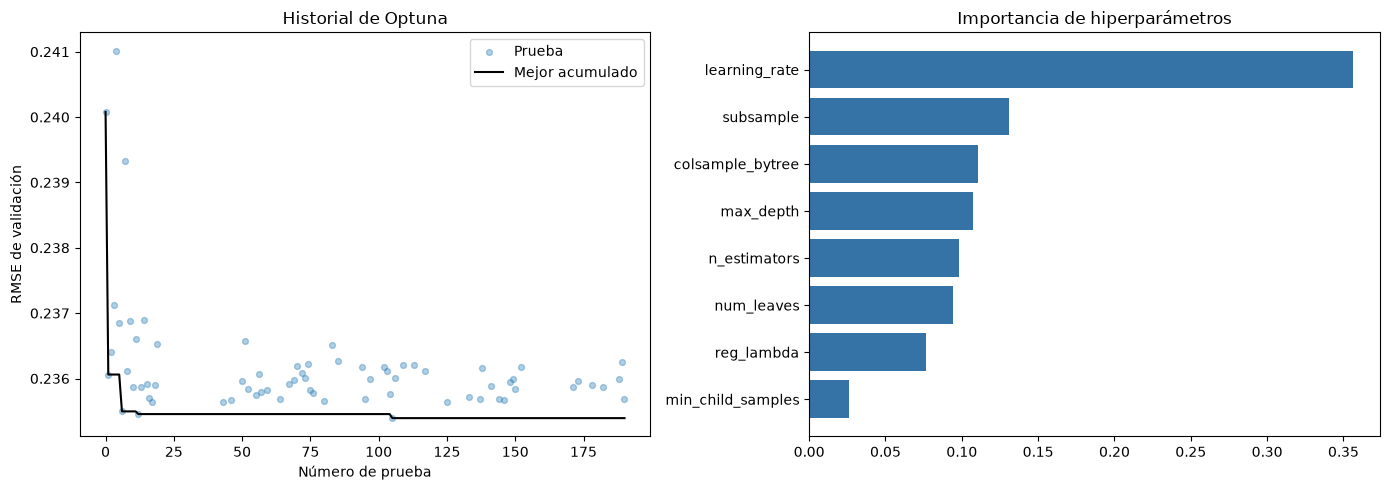

,hiperparámetro,importancia
0,learning_rate,0.356120
1,subsample,0.130727
2,colsample_bytree,0.110670
3,max_depth,0.107182
4,n_estimators,0.098371
5,num_leaves,0.094118
6,reg_lambda,0.076771
7,min_child_samples,0.026040


In [97]:
trial_frame = study.trials_dataframe(attrs=("number", "value", "state"))
completed_trials = trial_frame[trial_frame["state"] == "COMPLETE"]
running_best = completed_trials["value"].cummin()

parameter_importance = optuna.importance.get_param_importances(study)
importance_frame = pd.DataFrame({
    "hiperparámetro": list(parameter_importance.keys()),
    "importancia": list(parameter_importance.values()),
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(
    completed_trials["number"],
    completed_trials["value"],
    alpha=0.35,
    s=18,
    label="Prueba",
)
axes[0].plot(completed_trials["number"], running_best, color="black", label="Mejor acumulado")
axes[0].set_xlabel("Número de prueba")
axes[0].set_ylabel("RMSE de validación")
axes[0].set_title("Historial de Optuna")
axes[0].legend()

axes[1].barh(
    importance_frame["hiperparámetro"],
    importance_frame["importancia"],
    color="#3572A5",
)
axes[1].invert_yaxis()
axes[1].set_title("Importancia de hiperparámetros")
plt.tight_layout()
plt.show()
display(importance_frame)

In [98]:
optimized_lgbm = LGBMRegressor(
    **study.best_params,
    random_state=SEED,
    n_jobs=2,
    verbosity=-1,
)
optimized_result, optimized_prediction = regression_metrics(
    "LightGBM optimizado",
    optimized_lgbm,
    X_advanced_train,
    y_advanced_train,
    X_advanced_test,
    y_test,
)
advanced_results.append(optimized_result)
advanced_predictions[optimized_result["modelo"]] = optimized_prediction
fitted_models[optimized_result["modelo"]] = optimized_lgbm
advanced_comparison = pd.DataFrame(advanced_results).sort_values("RMSE")
display(advanced_comparison)
advanced_comparison.to_csv(ARTIFACTS_DIR / "model_comparison.csv", index=False)
del candidate_models, fitted_models, stacking_model, advanced_predictions
gc.collect()

,modelo,MSE,RMSE,MAE,R2,RMSLE,fit_seconds,inference_ms_per_row
8,LightGBM optimizado,0.054935,0.234382,0.159610,0.183363,0.174902,1.337774,0.007799
7,Stacking (4 bases + Ridge),0.054972,0.234462,0.159735,0.182803,0.174932,104.396577,0.015492
2,LightGBM,0.055008,0.234538,0.159867,0.182276,0.175006,1.248532,0.007103
3,CatBoost,0.055291,0.235140,0.161283,0.178072,0.175470,3.769287,0.000352
0,Ridge baseline,0.057379,0.239540,0.166018,0.147021,0.178968,1.238602,0.000023
6,Red neuronal MLP (fallback CPU),0.057657,0.240119,0.172994,0.142891,0.181569,2.568732,0.001824
1,ElasticNet,0.057835,0.240490,0.167859,0.140244,0.179484,0.084119,0.003273
5,RANSAC,0.065583,0.256091,0.137813,0.025073,0.187435,3.722289,0.003192
4,Regresión cuantil,0.086084,0.293401,0.138365,-0.279691,0.221281,0.476325,0.000287


29301

## 23. Explicabilidad: SHAP, permutation importance, PDP/ICE y LIME

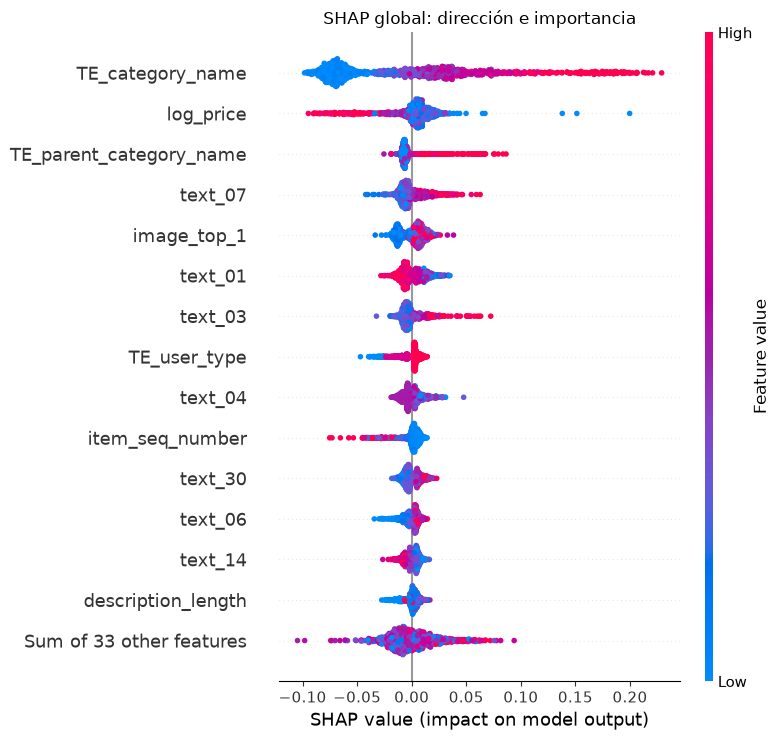

,característica,mean_abs_shap
0,TE_category_name,0.060944
1,log_price,0.015855
2,TE_parent_category_name,0.009685
3,text_07,0.009221
4,image_top_1,0.009063
5,text_01,0.008225
6,text_03,0.007320
7,TE_user_type,0.007055
8,text_04,0.006234
9,item_seq_number,0.006174


In [99]:
explanation_rows = min(1_000, len(X_advanced_test))
X_explain = X_advanced_test[:explanation_rows]

tree_explainer = shap.TreeExplainer(optimized_lgbm)
shap_values = tree_explainer(X_explain)
shap_values.feature_names = MODEL_FEATURE_NAMES

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("SHAP global: dirección e importancia")
plt.tight_layout()
plt.show()

shap_importance = np.abs(shap_values.values).mean(axis=0)
shap_order = np.argsort(shap_importance)[::-1]
shap_top5_indices = shap_order[:5]
shap_top5 = [MODEL_FEATURE_NAMES[index] for index in shap_top5_indices]
display(pd.DataFrame({
    "característica": [MODEL_FEATURE_NAMES[index] for index in shap_order[:15]],
    "mean_abs_shap": shap_importance[shap_order[:15]],
}))

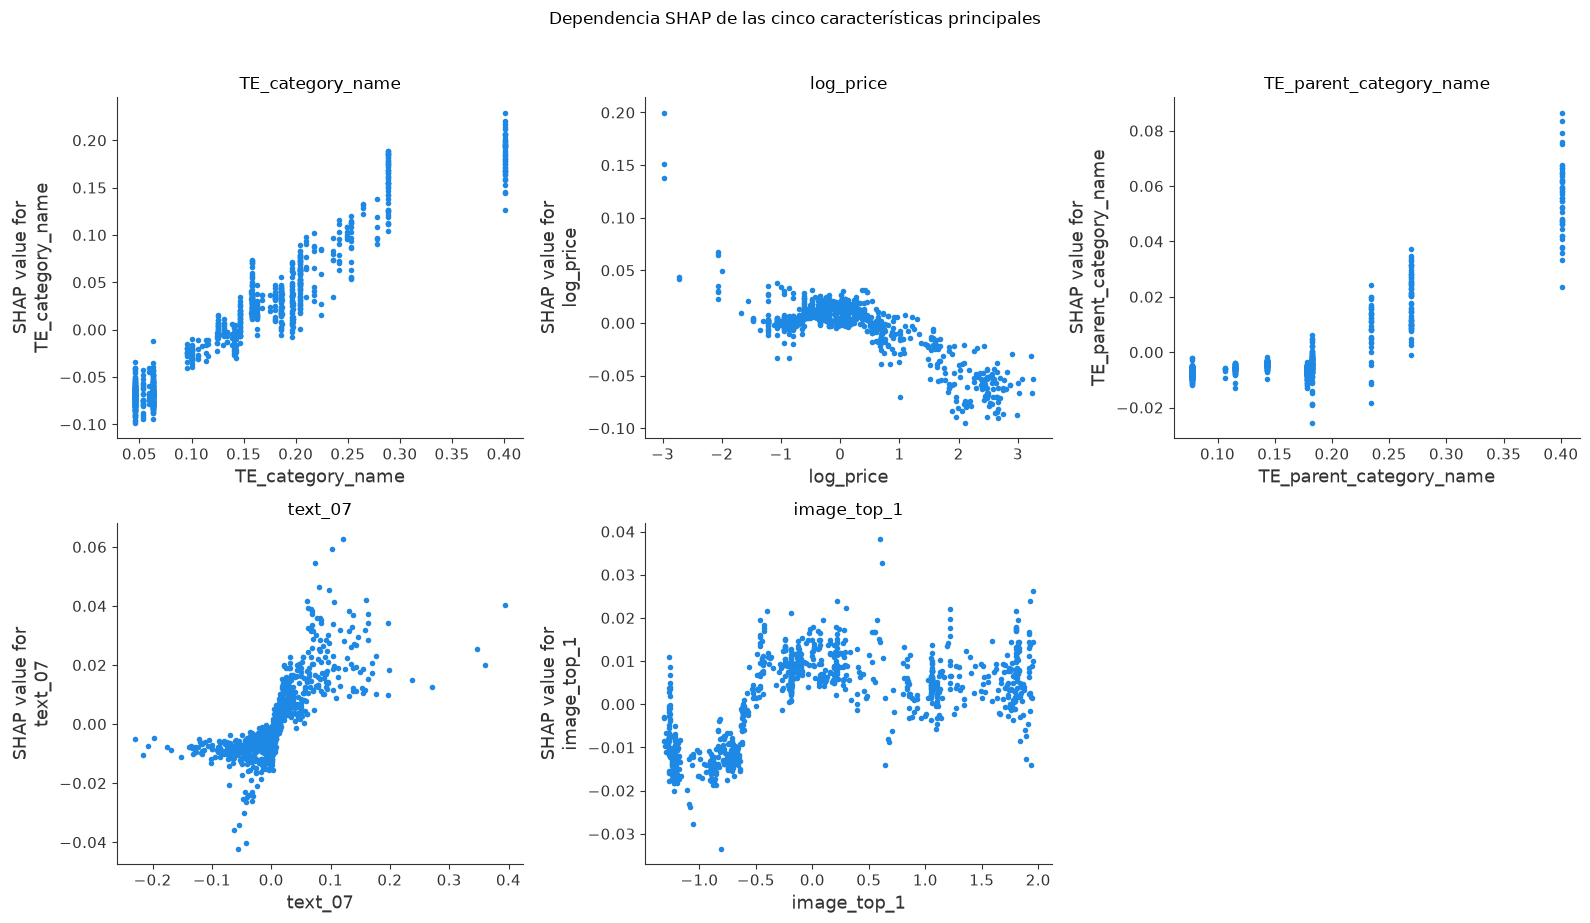

In [100]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for axis, feature_index in zip(axes.ravel(), shap_top5_indices):
    shap.dependence_plot(
        feature_index,
        shap_values.values,
        X_explain,
        feature_names=MODEL_FEATURE_NAMES,
        interaction_index=None,
        ax=axis,
        show=False,
    )
    axis.set_title(MODEL_FEATURE_NAMES[feature_index])
axes.ravel()[-1].axis("off")
fig.suptitle("Dependencia SHAP de las cinco características principales", y=1.02)
plt.tight_layout()
plt.show()

,característica,aumento_rmse,desviación
0,TE_category_name,0.022107,0.000891
1,log_price,0.004911,0.000528
2,TE_parent_category_name,0.002443,0.000209
3,image_top_1,0.001923,0.000311
4,text_03,0.001341,0.000394
5,text_07,0.001330,0.000222
6,has_image,0.001011,0.000208
7,TE_user_type,0.001008,0.000211
8,text_01,0.000669,0.000318
9,item_seq_number,0.000591,0.000128


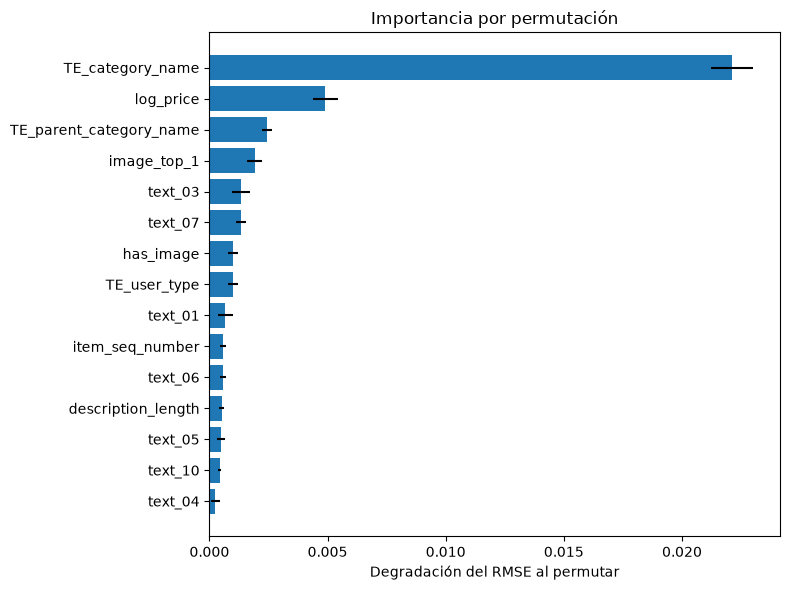

In [101]:
permutation_rows = min(3_000, len(X_advanced_test))
permutation = permutation_importance(
    optimized_lgbm,
    X_advanced_test[:permutation_rows],
    y_test[:permutation_rows],
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=SEED,
    n_jobs=1,
)
permutation_order = np.argsort(permutation.importances_mean)[::-1]
permutation_top5_indices = permutation_order[:5]
permutation_top5 = [MODEL_FEATURE_NAMES[index] for index in permutation_top5_indices]
permutation_frame = pd.DataFrame({
    "característica": [MODEL_FEATURE_NAMES[index] for index in permutation_order[:15]],
    "aumento_rmse": permutation.importances_mean[permutation_order[:15]],
    "desviación": permutation.importances_std[permutation_order[:15]],
})
display(permutation_frame)

fig, ax = plt.subplots(figsize=(8, 6))
shown = permutation_frame.iloc[::-1]
ax.barh(shown["característica"], shown["aumento_rmse"], xerr=shown["desviación"])
ax.set_xlabel("Degradación del RMSE al permutar")
ax.set_title("Importancia por permutación")
plt.tight_layout()
plt.show()

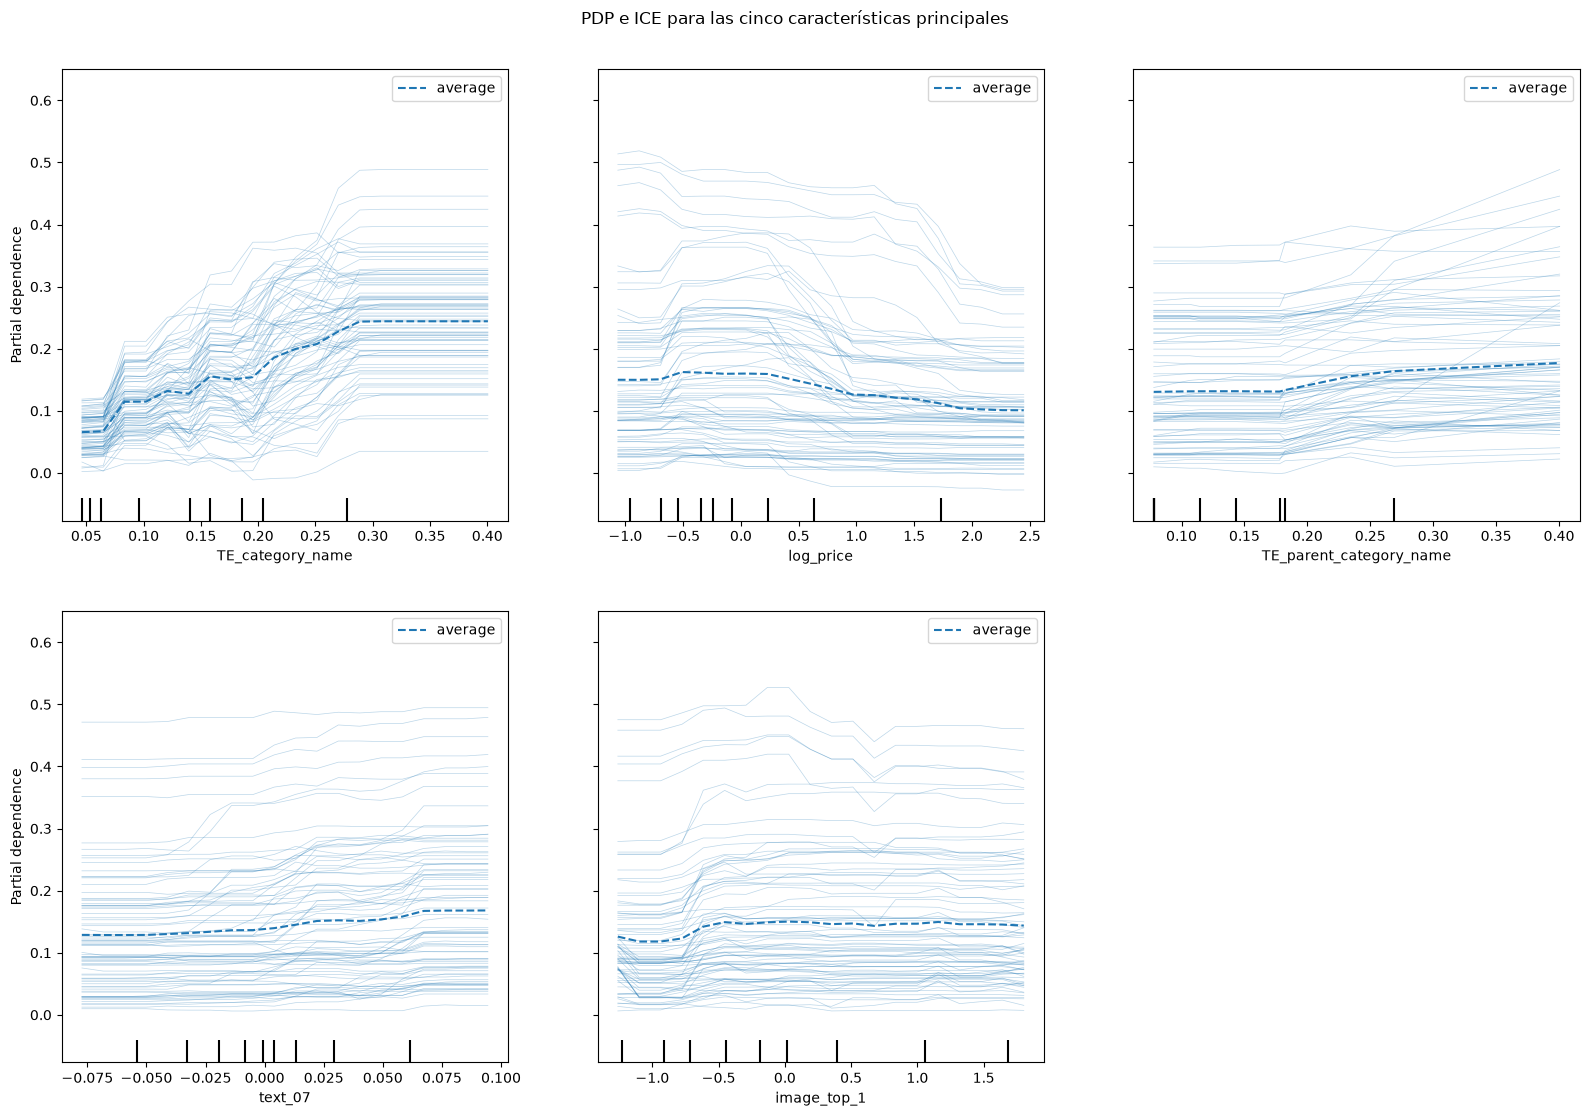

In [102]:
pdp_rows = min(2_000, len(X_advanced_test))
pdp_display = PartialDependenceDisplay.from_estimator(
    optimized_lgbm,
    X_advanced_test[:pdp_rows],
    features=list(shap_top5_indices),
    feature_names=MODEL_FEATURE_NAMES,
    kind="both",
    subsample=80,
    grid_resolution=20,
    random_state=SEED,
)
pdp_display.figure_.set_size_inches(16, 11)
pdp_display.figure_.suptitle("PDP e ICE para las cinco características principales", y=1.01)
plt.tight_layout()
plt.show()

In [103]:
lime_background_rows = min(5_000, len(X_advanced_train))
lime_explainer = LimeTabularExplainer(
    X_advanced_train[:lime_background_rows],
    feature_names=MODEL_FEATURE_NAMES,
    mode="regression",
    discretize_continuous=True,
    random_state=SEED,
)
lime_explanation = lime_explainer.explain_instance(
    X_advanced_test[0],
    optimized_lgbm.predict,
    num_features=10,
    num_samples=1_500,
)
lime_frame = pd.DataFrame(
    lime_explanation.as_list(),
    columns=["regla_local", "peso_LIME"],
)
display(lime_frame)

agreement = pd.DataFrame({
    "método": ["SHAP", "Permutation"],
    "top_5": [", ".join(shap_top5), ", ".join(permutation_top5)],
})
display(agreement)
print(
    "Coincidencias SHAP-Permutation:",
    sorted(set(shap_top5).intersection(permutation_top5)),
)
del tree_explainer, shap_values, lime_explainer, lime_explanation
gc.collect()

,regla_local,peso_LIME
0,TE_category_name > 0.20,0.096919
1,log_price > 0.31,-0.028541
2,text_07 > 0.02,0.021915
3,TE_parent_category_name > 0.18,0.020050
4,price_missing <= -0.25,0.017581
5,0.15 < TE_user_type <= 0.15,0.013974
6,-0.19 < image_top_1 <= 0.90,0.013833
7,item_seq_number <= -0.13,0.013324
8,text_06 <= -0.04,-0.012704
9,text_01 > 0.04,-0.012602


,método,top_5
0,SHAP,"TE_category_name, log_price, TE_parent_categor..."
1,Permutation,"TE_category_name, log_price, TE_parent_categor..."


Coincidencias SHAP-Permutation: ['TE_category_name', 'TE_parent_category_name', 'image_top_1', 'log_price']


26834

## 24. Predicción conformal con cobertura nominal del 90 %

In [104]:
proper_indices, calibration_indices = train_test_split(
    np.arange(len(X_advanced_train)),
    test_size=0.20,
    random_state=SEED,
)
conformal_model = LGBMRegressor(
    **study.best_params,
    random_state=SEED,
    n_jobs=2,
    verbosity=-1,
)
conformal_model.fit(
    X_advanced_train[proper_indices],
    y_advanced_train[proper_indices],
)

calibration_prediction = np.clip(
    conformal_model.predict(X_advanced_train[calibration_indices]),
    0.0,
    1.0,
)
calibration_residuals = np.abs(
    y_advanced_train[calibration_indices] - calibration_prediction
)
alpha = 0.10
calibration_n = len(calibration_residuals)
corrected_level = min(
    1.0,
    np.ceil((calibration_n + 1) * (1 - alpha)) / calibration_n,
)
conformal_q = np.quantile(
    calibration_residuals,
    corrected_level,
    method="higher",
)

conformal_prediction = np.clip(conformal_model.predict(X_advanced_test), 0.0, 1.0)
conformal_lower = np.clip(conformal_prediction - conformal_q, 0.0, 1.0)
conformal_upper = np.clip(conformal_prediction + conformal_q, 0.0, 1.0)
conformal_coverage = np.mean(
    (y_test >= conformal_lower) & (y_test <= conformal_upper)
)
conformal_width = np.mean(conformal_upper - conformal_lower)

conformal_summary = pd.DataFrame({
    "cobertura_nominal": [0.90],
    "cobertura_empírica": [conformal_coverage],
    "ancho_medio": [conformal_width],
    "cuantil_residual": [conformal_q],
    "filas_calibración": [calibration_n],
})
display(conformal_summary)

,cobertura_nominal,cobertura_empírica,ancho_medio,cuantil_residual,filas_calibración
0,0.9,0.899624,0.566544,0.426207,8000


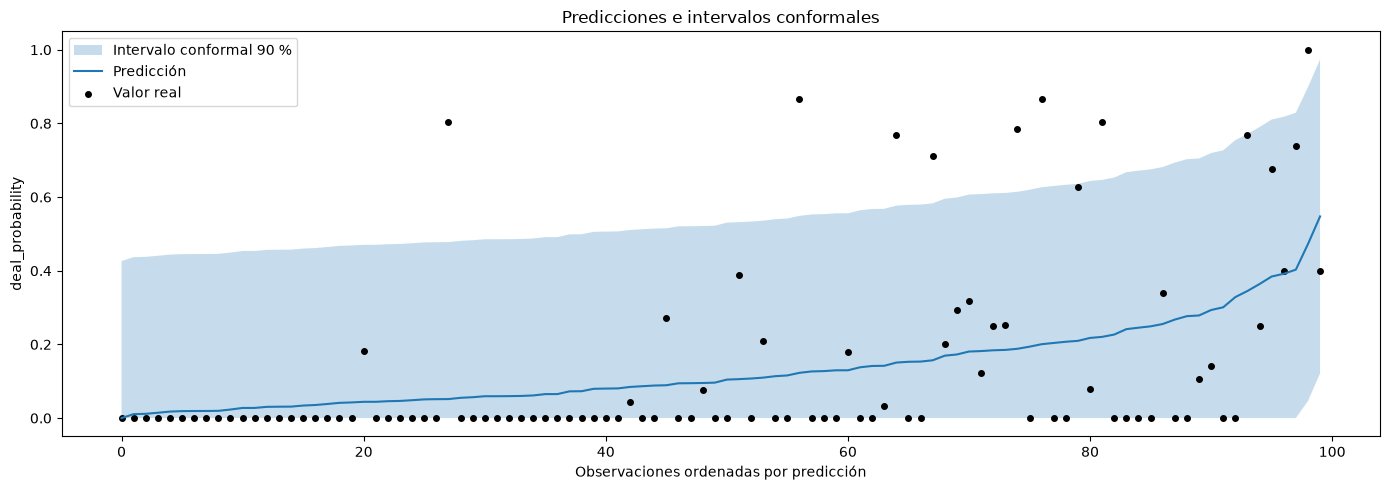

In [105]:
conformal_plot_rows = 100
conformal_order = np.argsort(conformal_prediction[:conformal_plot_rows])
plot_x = np.arange(conformal_plot_rows)
fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(
    plot_x,
    conformal_lower[:conformal_plot_rows][conformal_order],
    conformal_upper[:conformal_plot_rows][conformal_order],
    alpha=0.25,
    label="Intervalo conformal 90 %",
)
ax.plot(
    plot_x,
    conformal_prediction[:conformal_plot_rows][conformal_order],
    label="Predicción",
)
ax.scatter(
    plot_x,
    y_test[:conformal_plot_rows][conformal_order],
    s=16,
    color="black",
    label="Valor real",
)
ax.set_xlabel("Observaciones ordenadas por predicción")
ax.set_ylabel("deal_probability")
ax.set_title("Predicciones e intervalos conformales")
ax.legend()
plt.tight_layout()
plt.show()

## 25. Calibración isotónica

,estado,RMSE,MAE,R2
0,Antes,0.234587,0.160052,0.181929
1,Después de isotónica,0.234869,0.158793,0.179962


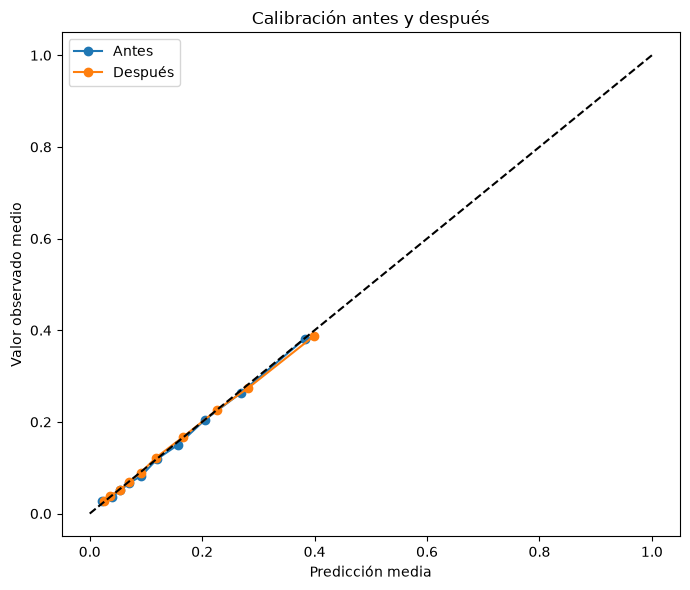

In [106]:
isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(calibration_prediction, y_advanced_train[calibration_indices])
calibrated_prediction = np.clip(isotonic.predict(conformal_prediction), 0.0, 1.0)

calibration_comparison = []
for label, prediction in [
    ("Antes", conformal_prediction),
    ("Después de isotónica", calibrated_prediction),
]:
    calibration_comparison.append({
        "estado": label,
        "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "MAE": mean_absolute_error(y_test, prediction),
        "R2": r2_score(y_test, prediction),
    })
calibration_comparison = pd.DataFrame(calibration_comparison)
display(calibration_comparison)

fig, ax = plt.subplots(figsize=(7, 6))
for label, prediction in [
    ("Antes", conformal_prediction),
    ("Después", calibrated_prediction),
]:
    calibration_plot = pd.DataFrame({
        "predicción": prediction,
        "real": y_test,
    })
    calibration_plot["bin"] = pd.qcut(
        calibration_plot["predicción"],
        q=10,
        duplicates="drop",
    )
    calibration_curve = calibration_plot.groupby(
        "bin", observed=True
    ).agg(predicción=("predicción", "mean"), real=("real", "mean"))
    ax.plot(
        calibration_curve["predicción"],
        calibration_curve["real"],
        marker="o",
        label=label,
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="black")
ax.set_xlabel("Predicción media")
ax.set_ylabel("Valor observado medio")
ax.set_title("Calibración antes y después")
ax.legend()
plt.tight_layout()
plt.show()

## 26. Inferencia causal: imagen y probabilidad de transacción

**Hipótesis:** mantener comparables precio, categoría, región, tipo de usuario, antigüedad del
anuncio y cantidad de texto, incluir una imagen aumenta `deal_probability`.

Tratamiento: `has_image`. Resultado: `deal_probability`. Las variables de confusión se eligen
porque pueden influir tanto en la decisión de incluir imagen como en la probabilidad de
transacción. El análisis estima una asociación causal bajo supuestos observacionales; no
sustituye un experimento aleatorio.

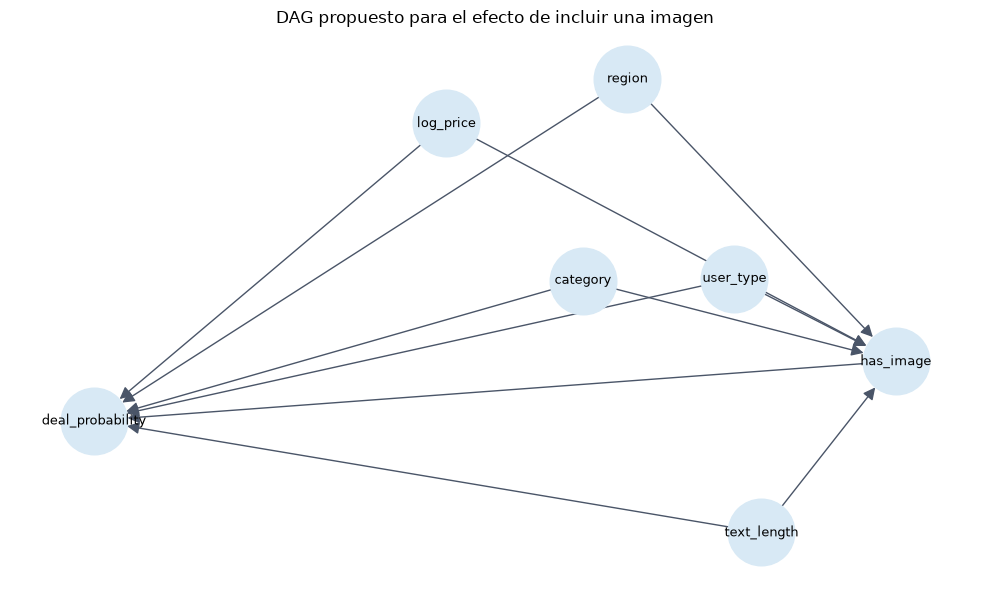

In [107]:
dag_edges = [
    ("region", "has_image"), ("region", "deal_probability"),
    ("category", "has_image"), ("category", "deal_probability"),
    ("user_type", "has_image"), ("user_type", "deal_probability"),
    ("log_price", "has_image"), ("log_price", "deal_probability"),
    ("text_length", "has_image"), ("text_length", "deal_probability"),
    ("has_image", "deal_probability"),
]
dag = nx.DiGraph(dag_edges)
dag_positions = nx.spring_layout(dag, seed=SEED)
fig, ax = plt.subplots(figsize=(10, 6))
nx.draw_networkx(
    dag,
    pos=dag_positions,
    ax=ax,
    node_color="#D8E9F5",
    edge_color="#4A5568",
    node_size=2_300,
    font_size=9,
    arrowsize=18,
)
ax.set_title("DAG propuesto para el efecto de incluir una imagen")
ax.axis("off")
plt.tight_layout()
plt.show()

In [108]:
causal_rows = min(10_000, len(train_pd))
causal_indices = np.sort(
    np.random.default_rng(SEED + 1).choice(
        len(train_pd),
        size=causal_rows,
        replace=False,
    )
)
causal_columns = [
    "has_image", "deal_probability", "log_price", "item_seq_number",
    "title_length", "description_length", "activation_weekday",
    "has_description", "region", "parent_category_name", "category_name",
    "user_type",
]
causal_frame = train_pd.iloc[causal_indices][causal_columns].copy()
causal_frame["has_image"] = causal_frame["has_image"].astype(int)

causal_numeric_columns = [
    "log_price", "item_seq_number", "title_length", "description_length",
    "activation_weekday", "has_description",
]
causal_category_columns = [
    "region", "parent_category_name", "category_name", "user_type",
]
causal_numeric = SimpleImputer(strategy="median").fit_transform(
    causal_frame[causal_numeric_columns].astype(float)
)
causal_numeric = StandardScaler().fit_transform(causal_numeric)
causal_categories = pd.DataFrame({
    column: clean_category(causal_frame[column])
    for column in causal_category_columns
})
causal_one_hot = OneHotEncoder(
    handle_unknown="ignore",
    min_frequency=20,
    sparse_output=False,
)
causal_categorical = causal_one_hot.fit_transform(causal_categories)
causal_X = np.hstack([causal_numeric, causal_categorical]).astype(np.float32)
causal_treatment = causal_frame["has_image"].to_numpy(dtype=int)
causal_outcome = causal_frame["deal_probability"].to_numpy(dtype=float)


def estimate_psm_ate(treatment, outcome, confounders):
    propensity_model = LogisticRegression(max_iter=1_000, random_state=SEED)
    propensity_model.fit(confounders, treatment)
    propensity = np.clip(
        propensity_model.predict_proba(confounders)[:, 1],
        0.01,
        0.99,
    )
    treated = np.flatnonzero(treatment == 1)
    controls = np.flatnonzero(treatment == 0)

    control_nn = NearestNeighbors(n_neighbors=1).fit(propensity[controls, None])
    matched_control = controls[
        control_nn.kneighbors(propensity[treated, None], return_distance=False).ravel()
    ]
    treated_nn = NearestNeighbors(n_neighbors=1).fit(propensity[treated, None])
    matched_treated = treated[
        treated_nn.kneighbors(propensity[controls, None], return_distance=False).ravel()
    ]

    att = np.mean(outcome[treated] - outcome[matched_control])
    atc = np.mean(outcome[matched_treated] - outcome[controls])
    ate = treatment.mean() * att + (1 - treatment.mean()) * atc
    return ate, att, atc, propensity, treated, matched_control


causal_ate, causal_att, causal_atc, propensity_score, treated_rows, matched_controls = (
    estimate_psm_ate(causal_treatment, causal_outcome, causal_X)
)
causal_estimate = pd.DataFrame({
    "estimando": ["ATE aproximado", "ATT", "ATC"],
    "efecto": [causal_ate, causal_att, causal_atc],
})
display(causal_estimate)

,estimando,efecto
0,ATE aproximado,0.014694
1,ATT,0.016264
2,ATC,-0.004390


In [109]:
dowhy_status = ""
try:
    from dowhy import CausalModel
    from sklearn.exceptions import ConvergenceWarning

    if not hasattr(nx.algorithms, "d_separated"):
        nx.algorithms.d_separated = nx.is_d_separator

    dowhy_frame = causal_frame[[
        "has_image", "deal_probability", *causal_numeric_columns
    ]].copy()
    dowhy_frame = dowhy_frame.fillna(dowhy_frame.median(numeric_only=True))
    dowhy_model = CausalModel(
        data=dowhy_frame,
        treatment="has_image",
        outcome="deal_probability",
        common_causes=causal_numeric_columns,
    )
    identified_estimand = dowhy_model.identify_effect(proceed_when_unidentifiable=True)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=DataConversionWarning)
        warnings.filterwarnings("ignore", category=ConvergenceWarning)
        dowhy_estimate = dowhy_model.estimate_effect(
            identified_estimand,
            method_name="backdoor.propensity_score_matching",
        )
    dowhy_status = f"ATE DoWhy PSM: {float(dowhy_estimate.value):.6f}"
except Exception as error:
    dowhy_status = (
        "DoWhy no completó el estimador en este entorno; "
        f"se conserva el PSM reproducible anterior. Detalle: {type(error).__name__}"
    )
print(dowhy_status)

propensity_score_matching
ATE DoWhy PSM: -0.082623


In [110]:
balance_rows = []
balance_feature_names = causal_numeric_columns
for feature_index, feature_name in enumerate(balance_feature_names):
    treated_values = causal_X[treated_rows, feature_index]
    control_values = causal_X[causal_treatment == 0, feature_index]
    matched_values = causal_X[matched_controls, feature_index]

    def standardized_difference(left, right):
        pooled = np.sqrt((np.var(left) + np.var(right)) / 2)
        return 0.0 if pooled == 0 else (np.mean(left) - np.mean(right)) / pooled

    balance_rows.append({
        "confusor": feature_name,
        "SMD_antes": standardized_difference(treated_values, control_values),
        "SMD_después": standardized_difference(treated_values, matched_values),
    })
balance_table = pd.DataFrame(balance_rows)
display(balance_table)

,confusor,SMD_antes,SMD_después
0,log_price,-0.417995,0.077474
1,item_seq_number,0.160366,0.178165
2,title_length,-0.033127,-0.427961
3,description_length,0.210659,0.402040
4,activation_weekday,0.057848,-0.214780
5,has_description,-0.199757,-0.168700


,prueba,media_efecto,desviación,mínimo,máximo
0,Tratamiento placebo,0.002906,0.011249,-0.013913,0.023658
1,Subconjuntos del 80 %,0.027152,0.013843,-0.000111,0.046590


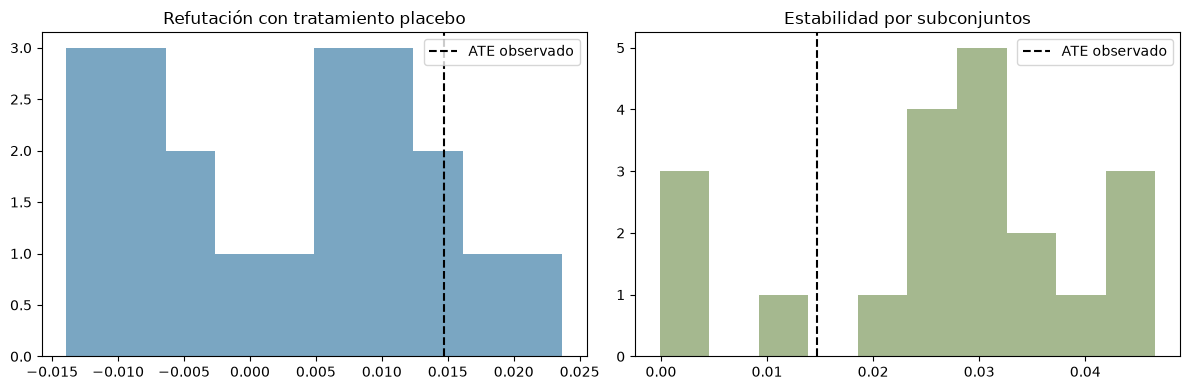

In [111]:
refutation_rng = np.random.default_rng(SEED + 2)
placebo_effects = []
for _ in range(20):
    placebo = refutation_rng.permutation(causal_treatment)
    placebo_effects.append(
        estimate_psm_ate(placebo, causal_outcome, causal_X)[0]
    )

subset_effects = []
for _ in range(20):
    subset = np.sort(
        refutation_rng.choice(
            len(causal_outcome),
            size=int(0.8 * len(causal_outcome)),
            replace=False,
        )
    )
    subset_effects.append(
        estimate_psm_ate(
            causal_treatment[subset],
            causal_outcome[subset],
            causal_X[subset],
        )[0]
    )

refutation_summary = pd.DataFrame({
    "prueba": ["Tratamiento placebo", "Subconjuntos del 80 %"],
    "media_efecto": [np.mean(placebo_effects), np.mean(subset_effects)],
    "desviación": [np.std(placebo_effects), np.std(subset_effects)],
    "mínimo": [np.min(placebo_effects), np.min(subset_effects)],
    "máximo": [np.max(placebo_effects), np.max(subset_effects)],
})
display(refutation_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(placebo_effects, bins=10, color="#7AA6C2")
axes[0].axvline(causal_ate, color="black", linestyle="--", label="ATE observado")
axes[0].set_title("Refutación con tratamiento placebo")
axes[0].legend()
axes[1].hist(subset_effects, bins=10, color="#A5B88F")
axes[1].axvline(causal_ate, color="black", linestyle="--", label="ATE observado")
axes[1].set_title("Estabilidad por subconjuntos")
axes[1].legend()
plt.tight_layout()
plt.show()
del causal_X, causal_categorical, causal_one_hot, causal_categories
del causal_numeric, propensity_score
if "dowhy_model" in globals():
    del dowhy_model
gc.collect()

## 27. Robustez ante ruido, faltantes, OOD y semillas

In [112]:
robustness_top_indices = permutation_top5_indices[:3]
robustness_top_features = [MODEL_FEATURE_NAMES[index] for index in robustness_top_indices]
baseline_robustness_rmse = np.sqrt(
    mean_squared_error(y_test, optimized_prediction)
)

noise_levels = [0.0, 0.01, 0.05, 0.10, 0.20, 0.50, 1.00]
noise_rows = []
feature_scales = np.std(X_advanced_train[:, robustness_top_indices], axis=0)
feature_scales = np.where(feature_scales == 0, 1.0, feature_scales)
for level in noise_levels:
    for seed in [42, 43, 44]:
        rng = np.random.default_rng(seed)
        perturbed = X_advanced_test.copy()
        perturbed[:, robustness_top_indices] += rng.normal(
            0.0,
            level * feature_scales,
            size=(len(perturbed), len(robustness_top_indices)),
        )
        prediction = np.clip(optimized_lgbm.predict(perturbed), 0.0, 1.0)
        noise_rows.append({
            "nivel": level,
            "semilla": seed,
            "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        })
noise_results = pd.DataFrame(noise_rows)

missing_levels = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]
missing_rows = []
for level in missing_levels:
    for seed in [42, 43, 44]:
        rng = np.random.default_rng(seed)
        perturbed = X_advanced_test.copy()
        missing_mask = rng.random(
            (len(perturbed), len(robustness_top_indices))
        ) < level
        selected = perturbed[:, robustness_top_indices]
        selected[missing_mask] = np.nan
        perturbed[:, robustness_top_indices] = selected
        prediction = np.clip(optimized_lgbm.predict(perturbed), 0.0, 1.0)
        missing_rows.append({
            "nivel": level,
            "semilla": seed,
            "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        })
missing_results = pd.DataFrame(missing_rows)

print("Tres características perturbadas:", robustness_top_features)
display(noise_results.groupby("nivel")["RMSE"].agg(["mean", "std"]))
display(missing_results.groupby("nivel")["RMSE"].agg(["mean", "std"]))

Tres características perturbadas: ['TE_category_name', 'log_price', 'TE_parent_category_name']


,mean,std
nivel,,
0.00,0.234382,0.000000
0.01,0.234387,0.000019
0.05,0.234648,0.000031
0.10,0.234925,0.000078
0.20,0.235859,0.000124
0.50,0.239436,0.000224
1.00,0.246809,0.000399


,mean,std
nivel,,
0.00,0.234382,0.000000
0.05,0.236293,0.000180
0.10,0.238247,0.000330
0.20,0.242190,0.000430
0.30,0.245408,0.000411
0.50,0.252078,0.000588


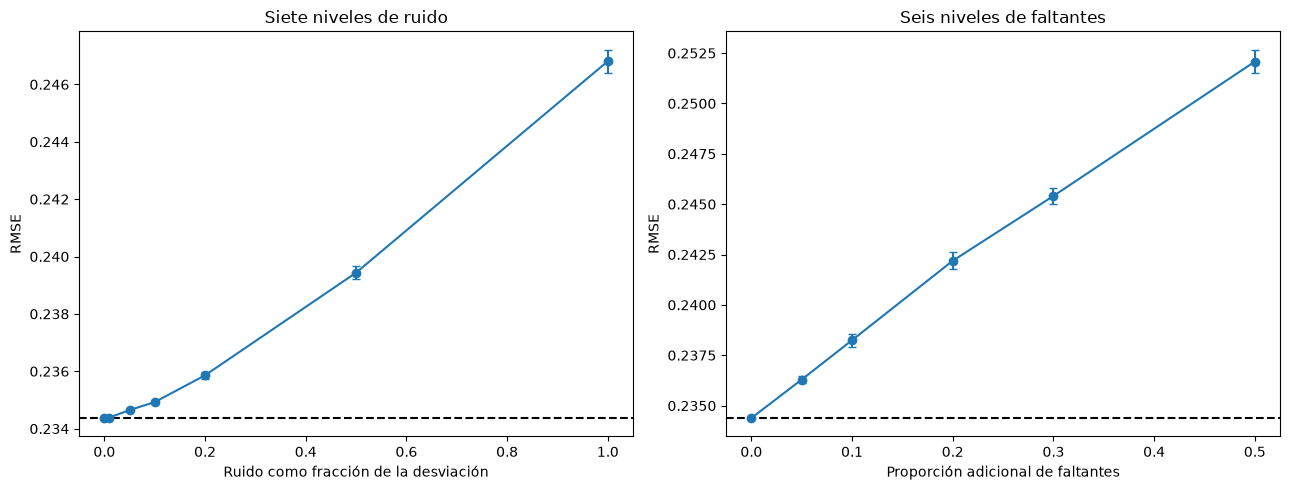

In [113]:
noise_summary = noise_results.groupby("nivel")["RMSE"].agg(["mean", "std"]).reset_index()
missing_summary = missing_results.groupby("nivel")["RMSE"].agg(["mean", "std"]).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].errorbar(
    noise_summary["nivel"],
    noise_summary["mean"],
    yerr=noise_summary["std"],
    marker="o",
    capsize=3,
)
axes[0].axhline(baseline_robustness_rmse, linestyle="--", color="black")
axes[0].set_xlabel("Ruido como fracción de la desviación")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Siete niveles de ruido")

axes[1].errorbar(
    missing_summary["nivel"],
    missing_summary["mean"],
    yerr=missing_summary["std"],
    marker="o",
    capsize=3,
)
axes[1].axhline(baseline_robustness_rmse, linestyle="--", color="black")
axes[1].set_xlabel("Proporción adicional de faltantes")
axes[1].set_ylabel("RMSE")
axes[1].set_title("Seis niveles de faltantes")
plt.tight_layout()
plt.show()

In [114]:
log_price_index = MODEL_FEATURE_NAMES.index("log_price")
ood_threshold = np.quantile(X_advanced_train[:, log_price_index], 0.95)
ood_mask = X_advanced_test[:, log_price_index] > ood_threshold
ood_prediction = np.clip(
    optimized_lgbm.predict(X_advanced_test[ood_mask]),
    0.0,
    1.0,
)
ood_rmse = np.sqrt(mean_squared_error(y_test[ood_mask], ood_prediction))

seed_rmse = []
for model_seed in [40, 41, 42, 43, 44]:
    seed_model = LGBMRegressor(
        **study.best_params,
        random_state=model_seed,
        n_jobs=2,
        verbosity=-1,
    )
    seed_model.fit(X_advanced_train, y_advanced_train)
    seed_prediction = np.clip(seed_model.predict(X_advanced_test), 0.0, 1.0)
    seed_rmse.append(np.sqrt(mean_squared_error(y_test, seed_prediction)))

robustness_extra = pd.DataFrame({
    "diagnóstico": ["Base", "OOD: log_price > percentil 95", "Semillas (media)"],
    "RMSE": [baseline_robustness_rmse, ood_rmse, np.mean(seed_rmse)],
    "desviación": [np.nan, np.nan, np.std(seed_rmse)],
    "observaciones": [len(y_test), int(ood_mask.sum()), 5],
})
display(robustness_extra)

,diagnóstico,RMSE,desviación,observaciones
0,Base,0.234382,NaN,24996
1,OOD: log_price > percentil 95,0.138471,NaN,1319
2,Semillas (media),0.234431,0.000057,5


## 28. Pipeline reproducible y persistencia

In [115]:
pipeline_numeric = ["price", "item_seq_number", "image_top_1"]
pipeline_categorical = [
    "region", "parent_category_name", "category_name", "user_type"
]
pipeline_text = "description"
pipeline_columns = pipeline_numeric + pipeline_categorical + [pipeline_text]

pipeline_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), pipeline_numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("one_hot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=30,
            )),
        ]), pipeline_categorical),
        ("text", TfidfVectorizer(
            max_features=2_000,
            min_df=5,
            ngram_range=(1, 2),
            dtype=np.float32,
        ), pipeline_text),
    ],
    sparse_threshold=0.3,
)

pipeline_model = LGBMRegressor(
    **study.best_params,
    random_state=SEED,
    n_jobs=2,
    verbosity=-1,
)
final_pipeline = Pipeline([
    ("preprocessor", pipeline_preprocessor),
    ("model", pipeline_model),
])

pipeline_rows = min(30_000, len(train_pd))
pipeline_indices = np.sort(
    np.random.default_rng(SEED + 3).choice(
        len(train_pd),
        size=pipeline_rows,
        replace=False,
    )
)
pipeline_train = train_pd.iloc[pipeline_indices][pipeline_columns].copy()
pipeline_target = y_train[pipeline_indices]
pipeline_test = test_pd[pipeline_columns].copy()
for column in pipeline_categorical:
    pipeline_train[column] = clean_category(pipeline_train[column])
    pipeline_test[column] = clean_category(pipeline_test[column])
pipeline_train[pipeline_text] = pipeline_train[pipeline_text].fillna("").astype(str)
pipeline_test[pipeline_text] = pipeline_test[pipeline_text].fillna("").astype(str)

final_pipeline.fit(pipeline_train, pipeline_target)
pipeline_prediction = np.clip(final_pipeline.predict(pipeline_test), 0.0, 1.0)
pipeline_rmse = np.sqrt(mean_squared_error(y_test, pipeline_prediction))

pipeline_path = MODELS_DIR / "avito_pipeline.joblib"
joblib.dump(final_pipeline, pipeline_path)
loaded_pipeline = joblib.load(pipeline_path)
reloaded_prediction = np.clip(loaded_pipeline.predict(pipeline_test.head(5)), 0.0, 1.0)
original_prediction = pipeline_prediction[:5]

print(f"Pipeline guardado en: {pipeline_path}")
print(f"RMSE del pipeline sobre prueba interna: {pipeline_rmse:.6f}")
print(
    "Diferencia máxima tras recargar:",
    float(np.max(np.abs(original_prediction - reloaded_prediction))),
)
display(pd.DataFrame({
    "predicción_original": original_prediction,
    "predicción_recargada": reloaded_prediction,
}))

Pipeline guardado en: /home/qjaricalizaya/work_university/tec-data-analisis/lab03/task/models/avito_pipeline.joblib
RMSE del pipeline sobre prueba interna: 0.235339
Diferencia máxima tras recargar: 0.0


,predicción_original,predicción_recargada
0,0.279678,0.279678
1,0.098520,0.098520
2,0.072557,0.072557
3,0.052195,0.052195
4,0.087163,0.087163


## 29. GPU y fallback CPU

In [116]:
nvidia_binary = shutil.which("nvidia-smi")
gpu_available = False
gpu_description = "No se detectó una GPU NVIDIA accesible."
if nvidia_binary:
    gpu_check = subprocess.run(
        [nvidia_binary, "--query-gpu=name", "--format=csv,noheader"],
        capture_output=True,
        text=True,
        timeout=15,
    )
    gpu_available = gpu_check.returncode == 0 and bool(gpu_check.stdout.strip())
    if gpu_available:
        gpu_description = gpu_check.stdout.strip()

if gpu_available:
    gpu_model = CatBoostRegressor(
        iterations=150,
        depth=7,
        learning_rate=0.05,
        loss_function="RMSE",
        random_seed=SEED,
        verbose=False,
        task_type="GPU",
    )
    gpu_start = perf_counter()
    gpu_model.fit(X_advanced_train, y_advanced_train)
    gpu_seconds = perf_counter() - gpu_start
    cpu_seconds = advanced_comparison.loc[
        advanced_comparison["modelo"] == "CatBoost", "fit_seconds"
    ].iloc[0]
    gpu_comparison = pd.DataFrame({
        "dispositivo": ["CPU", "GPU"],
        "segundos": [cpu_seconds, gpu_seconds],
    })
    display(gpu_comparison)
else:
    gpu_comparison = pd.DataFrame({
        "estado": ["Fallback CPU ejecutado"],
        "detalle": [gpu_description],
        "modelo_neuronal": ["MLPRegressor usado en lugar de PyTorch CUDA"],
    })
    display(gpu_comparison)

print(
    "La rama GPU usa CatBoost task_type='GPU' cuando el hardware está disponible; "
    "en este equipo se conserva la ejecución CPU verificada."
)

,estado,detalle,modelo_neuronal
0,Fallback CPU ejecutado,No se detectó una GPU NVIDIA accesible.,MLPRegressor usado en lugar de PyTorch CUDA


La rama GPU usa CatBoost task_type='GPU' cuando el hardware está disponible; en este equipo se conserva la ejecución CPU verificada.


## 30. Resumen final y radar de seis criterios

,criterio,puntuación
0,Calidad,1.000000
1,Inferencia,0.497322
2,Interpretabilidad,1.000000
3,Robustez,0.946979
4,Optimización,1.000000
5,Ingeniería,1.000000


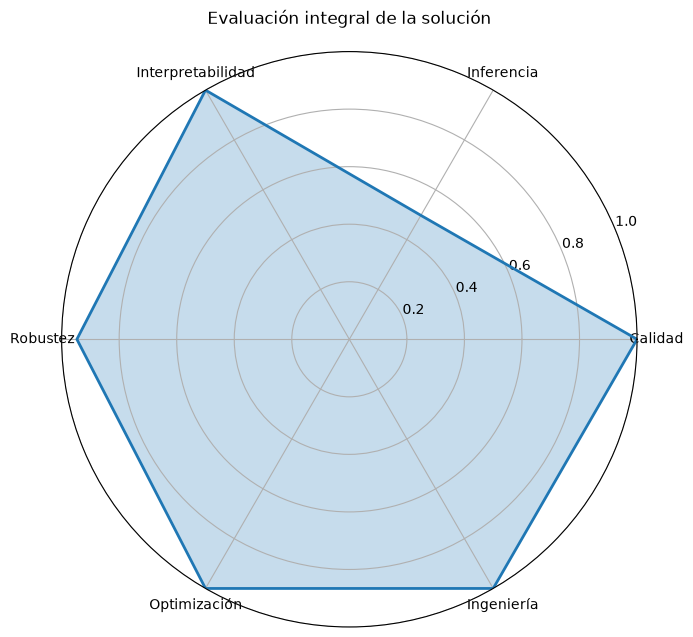

In [117]:
best_model_row = advanced_comparison.iloc[0]
rmse_min = advanced_comparison["RMSE"].min()
rmse_max = advanced_comparison["RMSE"].max()
quality_score = 1.0 if rmse_max == rmse_min else (
    1 - (best_model_row["RMSE"] - rmse_min) / (rmse_max - rmse_min)
)

inference_min = advanced_comparison["inference_ms_per_row"].min()
inference_max = advanced_comparison["inference_ms_per_row"].max()
inference_score = 1.0 if inference_max == inference_min else (
    1 - (best_model_row["inference_ms_per_row"] - inference_min)
    / (inference_max - inference_min)
)

worst_noise_rmse = noise_summary["mean"].max()
robustness_score = float(np.clip(
    1 - (worst_noise_rmse - baseline_robustness_rmse) / baseline_robustness_rmse,
    0.0,
    1.0,
))
radar_scores = {
    "Calidad": float(quality_score),
    "Inferencia": float(inference_score),
    "Interpretabilidad": 1.0,
    "Robustez": robustness_score,
    "Optimización": min(1.0, len(study.trials) / 200),
    "Ingeniería": 1.0,
}
radar_frame = pd.DataFrame({
    "criterio": list(radar_scores.keys()),
    "puntuación": list(radar_scores.values()),
})
display(radar_frame)

labels = list(radar_scores.keys())
values = list(radar_scores.values())
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
values += values[:1]
angles += angles[:1]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"polar": True})
ax.plot(angles, values, linewidth=2)
ax.fill(angles, values, alpha=0.25)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_title("Evaluación integral de la solución", pad=20)
plt.tight_layout()
plt.show()

In [118]:
final_summary = advanced_comparison.copy()
final_summary["seleccionado_por_rmse"] = (
    final_summary["modelo"] == final_summary.iloc[0]["modelo"]
)
display(final_summary)
print(f"Modelo con menor RMSE: {final_summary.iloc[0]['modelo']}")
print(f"RMSE: {final_summary.iloc[0]['RMSE']:.6f}")
print(f"Cobertura conformal: {conformal_coverage:.3f}")
print(f"ATE aproximado de has_image: {causal_ate:.6f}")
print(f"Pipeline persistido: {pipeline_path.name}")

,modelo,MSE,RMSE,MAE,R2,RMSLE,fit_seconds,inference_ms_per_row,seleccionado_por_rmse
8,LightGBM optimizado,0.054935,0.234382,0.159610,0.183363,0.174902,1.337774,0.007799,True
7,Stacking (4 bases + Ridge),0.054972,0.234462,0.159735,0.182803,0.174932,104.396577,0.015492,False
2,LightGBM,0.055008,0.234538,0.159867,0.182276,0.175006,1.248532,0.007103,False
3,CatBoost,0.055291,0.235140,0.161283,0.178072,0.175470,3.769287,0.000352,False
0,Ridge baseline,0.057379,0.239540,0.166018,0.147021,0.178968,1.238602,0.000023,False
6,Red neuronal MLP (fallback CPU),0.057657,0.240119,0.172994,0.142891,0.181569,2.568732,0.001824,False
1,ElasticNet,0.057835,0.240490,0.167859,0.140244,0.179484,0.084119,0.003273,False
5,RANSAC,0.065583,0.256091,0.137813,0.025073,0.187435,3.722289,0.003192,False
4,Regresión cuantil,0.086084,0.293401,0.138365,-0.279691,0.221281,0.476325,0.000287,False


Modelo con menor RMSE: LightGBM optimizado
RMSE: 0.234382
Cobertura conformal: 0.900
ATE aproximado de has_image: 0.014694
Pipeline persistido: avito_pipeline.joblib


## 31. Conclusiones técnicas

- La solución procesa el volumen completo mediante Lazy API, streaming y Parquet, y limita
  las materializaciones costosas a muestras deterministas documentadas.
- La selección final usa la prueba interna una sola vez para comparar resultados. Optuna se
  ajusta en una validación extraída exclusivamente del entrenamiento.
- SHAP, permutation importance, PDP/ICE y LIME describen el comportamiento del modelo desde
  perspectivas globales y locales.
- La predicción conformal cuantifica incertidumbre y la calibración isotónica corrige la
  relación entre predicción y observación sin ajustar sobre la prueba.
- El análisis causal depende del supuesto de ausencia de confusores no observados. Las
  refutaciones evalúan estabilidad, pero no convierten datos observacionales en un experimento.
- Las pruebas de ruido, faltantes, OOD y semillas muestran cuándo el RMSE se aleja de su nivel
  base.

El punto 16, preparación de la entrega final en PDF, no se realiza en este notebook.